# Processamento de imagens de SEM - Restauração, realce, relevo aparente e qualidade de imagem
### Calibração, correção da varredura, decomposição em escalas, restauração iterativa e análises paralelas (adaptado do fluxo de pticografia em foco)
>Autor:Abraham Contreras

## Como usar

Este notebook foi desenvolvido para o processamento e a análise de imagens de microscopia eletrônica de varredura (SEM 2D). Além de gerar a imagem final tratada, reúne análises complementares que permitem quantificar características de contraste, ruído, textura, resolução e morfologia da imagem.

Etapas do processamento em SEM

| Etapa | Descrição |
| --- | --- |
| Pré-processamento | Remoção da faixa de dados, correção do ruído de linha da varredura, pixels quentes e sombreamento do detector |
| Análise de frequência | Cálculo do espectro de potência (FFT) da imagem |
| Calibração | Determinação do tamanho do pixel por metadados, barra de escala ou valor manual |
| Filtragem em frequência | Decomposição da imagem em escalas por filtros circulares e anulares no espaço de Fourier |
| Recorte e binning | Seleção da região de interesse (ROI) e redução da resolução espacial |
| Análise de gradiente | Detecção de bordas, compressão do gradiente e estimativa de relevo aparente (shape-from-shading) |
| Restauração da imagem | Restauração iterativa Richardson-Lucy com regularização TV (PSF = feixe de elétrons) |
| Análise FFT | Comparação do espectro de frequência antes e depois da restauração |

Análises complementares incluídas

1. Diagnóstico da imagem: ruído, SNR, resolução efetiva e índice de ruído de linha.
2. Energia por escala: quantificação da variância da imagem em diferentes faixas de tamanho.
3. Mapa de contraste relativo (ΔI/I₀): visualização das variações relativas de intensidade.
4. Fases por níveis de cinza (multi-Otsu): determinação das frações de área e análise de sensibilidade aos limiares.
5. Largura de borda 10–90%: avaliação da borda mais intensa antes e depois da restauração.
6. Tabela de qualidade: comparação de SNR, nitidez e entropia entre todas as versões da imagem.
7. Autocorrelação 2D: determinação do comprimento de correlação e da anisotropia.
8. Rugosidade e textura local: análise do desvio padrão local, entropia e GLCM por fase.

Passos para utilização

1. Coloque este notebook e a imagem de SEM (`.tif`, `.png`, `.jpg` ou `.bmp`) na mesma pasta. Sem especificar um arquivo, o notebook utilizará a primeira imagem encontrada. Para selecionar outra, preencha `nome_imagem` na célula de caminhos.
2. Execute as células na ordem, de cima para baixo.
3. Calibração: o tamanho do pixel será obtido automaticamente dos metadados (FEI/Thermo Fisher ou Zeiss), quando disponíveis. Caso contrário, informe `tamanho_pixel_nm` ou o valor da barra de escala em `comprimento_barra_nm` (por exemplo, 1000 para uma barra de 1 µm). Sem calibração, os resultados serão apresentados em pixels.
4. Os resultados, incluindo imagens (`.tif`) e tabelas (`.csv`), serão salvos na mesma pasta, com `_SAIDA_` no nome dos arquivos.
5. O OpenCV (`cv2`) é opcional. Caso não esteja instalado, o notebook utilizará alternativas disponíveis no scikit-image.

# Agradecimentos e ressalvas

In [1]:
# Este tutorial foi adaptado por Abraham Contreras(guzmanabraham108@gmail.com)
# para imagens de SEM 2D:

# Não está totalmente otimizado.
# Seu objetivo é mostrar que funciona e que é divertido de usar!

In [ ]:
# Amostra cedida por cortesia da Abraham Contreras e Maria Vitória, da Ilum Escola de Ciência

**Se for util para você cite:**

> CONTRERAS, Abraham. Processamento de imagens de SEM: restauração, realce, relevo aparente e qualidade de imagem – calibração, correção da varredura, decomposição em escalas, restauração iterativa e análises paralelas. Código computacional.

# Início

In [2]:
# Importação das bibliotecas

import os
import re
import csv
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import patches
from matplotlib.colors import hsv_to_rgb
from types import SimpleNamespace

import tifffile
import scipy
from scipy import ndimage
from scipy.signal import fftconvolve
from scipy.special import expit
from scipy.spatial import cKDTree, Voronoi
from scipy.spatial.distance import pdist

import skimage
from skimage import exposure, restoration, filters, measure, segmentation, feature

# OpenCV é opcional: acelera a redução de ruído (Non-Local Means) e o CLAHE
try:
    import cv2
except ImportError:
    cv2 = None
    print('Aviso: OpenCV (cv2) não encontrado; serão usadas alternativas do scikit-image.')

# As bibliotecas do fluxo 4D-STEM (py4DSTEM, h5py, hdf5plugin) não são necessárias para imagens de SEM 2D.

In [3]:
# Definição dos caminhos do conjunto de dados

import os
from pathlib import Path


def obter_pasta_do_notebook():
    """Retorna a pasta onde este arquivo .ipynb está salvo."""

    # VS Code
    arquivo_vscode = globals().get('__vsc_ipynb_file__')
    if arquivo_vscode:
        return Path(arquivo_vscode).resolve().parent

    # JupyterLab / Jupyter Notebook
    sessao = os.environ.get('JPY_SESSION_NAME')
    if sessao and Path(sessao).is_absolute() and Path(sessao).exists():
        return Path(sessao).resolve().parent

    # Execução como script .py
    if '__file__' in globals():
        return Path(__file__).resolve().parent

    # Diretório de trabalho atual
    return Path.cwd().resolve()


# Pasta do notebook: todas as imagens devem estar nesta mesma pasta
pasta_notebook = obter_pasta_do_notebook()
print('Pasta do notebook (e das imagens):', pasta_notebook)

# Pasta (a mesma pasta do notebook, com separador final)
file_path = str(pasta_notebook) + os.sep

# Nome da imagem de SEM. Com None, usa a primeira imagem encontrada na pasta.
# Para analisar outra imagem, informe o nome (ex.: 'amostra_01.tif').
nome_imagem = None

extensoes_imagem = ('.tif', '.tiff', '.png', '.jpg', '.jpeg', '.bmp')
# Arquivos gerados por este notebook contêm '_SAIDA_' e são ignorados na busca; 'FF_*' são flatfields
candidatas = sorted(p.name for p in pasta_notebook.iterdir()
                    if p.suffix.lower() in extensoes_imagem and '_SAIDA_' not in p.name and not p.name.upper().startswith('FF_'))
print('Imagens encontradas na pasta:', candidatas)

if nome_imagem is None:
    if not candidatas:
        raise FileNotFoundError('Nenhuma imagem (' + ', '.join(extensoes_imagem) + ') encontrada em ' + str(pasta_notebook) +
                                '. Coloque a imagem de SEM na mesma pasta deste notebook.')
    nome_imagem = candidatas[0]

filename = file_path + nome_imagem
if not os.path.isfile(filename):
    raise FileNotFoundError('Imagem não encontrada: ' + filename + '. Coloque o arquivo na mesma pasta deste notebook.')
print('Imagem analisada:', nome_imagem)

Pasta do notebook (e das imagens): C:\JupyterLab\2-semestre\IP1\SEM
Imagens encontradas na pasta: ['MEV-NC_AM_BSE_005.tif']
Imagem analisada: MEV-NC_AM_BSE_005.tif


# Funções auxiliares
As células a seguir apenas definem funções (não processam a imagem).

In [4]:
# Funções auxiliares (1/4): leitura, calibração, faixa de dados e ruído de varredura

def ler_imagem_sem(caminho):
    """Lê uma imagem de SEM (TIFF, PNG, JPG ou BMP) e devolve uma matriz 2D, preservando o tipo de dado."""
    caminho = str(caminho)
    if caminho.lower().endswith(('.tif', '.tiff')):
        imagem = np.squeeze(tifffile.imread(caminho))
    else:
        from skimage import io as skio
        imagem = np.squeeze(skio.imread(caminho))
    if imagem.ndim == 3 and imagem.shape[-1] in (3, 4):
        # Imagem RGB(A) (comum em exportações): converte para tons de cinza
        imagem = imagem[..., :3].mean(axis=-1).astype(imagem.dtype)
    elif imagem.ndim == 3:
        print('Aviso: o arquivo contém', imagem.shape[0], 'quadros; usando apenas o primeiro.')
        imagem = imagem[0]
    if imagem.ndim != 2:
        raise ValueError('A imagem deve ser bidimensional; forma lida: ' + str(imagem.shape))
    return imagem


def _buscar_chave(obj, nome):
    """Busca recursivamente uma chave em dicionários e listas aninhados."""
    if isinstance(obj, dict):
        for k, v in obj.items():
            if str(k).lower() == nome.lower():
                return v
            r = _buscar_chave(v, nome)
            if r is not None:
                return r
    elif isinstance(obj, (list, tuple)):
        for v in obj:
            r = _buscar_chave(v, nome)
            if r is not None:
                return r
    return None


def _para_nm(valor, unidade):
    """Converte um comprimento para nanômetros."""
    unidade = str(unidade).strip().lower().replace('µ', 'u').replace('μ', 'u')
    fatores = {'m': 1e9, 'mm': 1e6, 'um': 1e3, 'nm': 1.0, 'pm': 1e-3, 'å': 0.1}
    return float(valor) * fatores.get(unidade, np.nan)


def _extrair_valor_unidade(v):
    """Extrai 'número + unidade' de um texto ou de uma lista de campos; devolve nm ou None."""
    itens = list(v) if isinstance(v, (list, tuple)) else [v]
    texto = ' '.join(str(i) for i in itens)
    m = re.search(r'([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)\s*(nm|um|µm|μm|mm|pm|Å|m)(?![a-zA-Z])', texto)
    return _para_nm(m.group(1), m.group(2)) if m else None


def ler_calibracao_metadados(caminho):
    """
    Tenta obter o tamanho do pixel (nm) dos metadados do TIFF (FEI/Thermo Fisher ou Zeiss).
    Devolve (nm por pixel, origem) ou (None, None).
    """
    try:
        with tifffile.TiffFile(str(caminho)) as tif:
            fei = getattr(tif, 'fei_metadata', None)
            if fei:
                v = _buscar_chave(fei, 'PixelWidth')
                if v is not None:
                    return float(v) * 1e9, 'metadados FEI/Thermo Fisher (PixelWidth)'
            sem = getattr(tif, 'sem_metadata', None)
            if sem:
                v = _buscar_chave(sem, 'ap_image_pixel_size')
                nm = _extrair_valor_unidade(v) if v is not None else None
                if nm is not None and np.isfinite(nm):
                    return nm, 'metadados Zeiss (ap_image_pixel_size)'
    except Exception:
        pass
    return None, None


def detectar_faixa_de_dados(imagem, fracao_max=0.30, tolerancia=2, fracao_plana=0.5):
    """
    Procura, no rodapé, a faixa de dados do microscópio (fundo uniforme com texto e barra de escala).
    Devolve {'linha_inicio', 'fundo'} ou None se não houver faixa.
    """
    h, w = imagem.shape
    modo_ref, inicio = None, h
    for r in range(h - 1, int(h * (1 - fracao_max)) - 1, -1):
        valores, contagens = np.unique(imagem[r], return_counts=True)
        modo = int(valores[np.argmax(contagens)])
        plana = float(np.mean(np.abs(imagem[r].astype(np.int64) - modo) <= tolerancia))
        if modo_ref is None:
            modo_ref = modo
        if plana >= fracao_plana and (abs(modo - modo_ref) <= 2 * tolerancia or plana >= 0.95):
            inicio = r
        else:
            break
    if h - inicio < 20:
        return None
    return {'linha_inicio': inicio, 'fundo': modo_ref}


def detectar_barra_de_escala_sem(imagem, faixa, largura_min=30):
    """Maior segmento horizontal contrastante dentro da faixa de dados (a barra de escala). Devolve comprimento em pixels."""
    regiao = imagem[faixa['linha_inicio']:].astype(np.int64)
    if np.issubdtype(imagem.dtype, np.integer):
        limite = 0.25 * float(np.iinfo(imagem.dtype).max)
    else:
        limite = 0.25 * float(imagem.max())
    diferente = np.abs(regiao - faixa['fundo']) > limite
    melhor, linha = 0, None
    for i in range(diferente.shape[0]):
        if not diferente[i].any():
            continue
        dif = np.diff(np.concatenate(([0], diferente[i].astype(np.int8), [0])))
        comprimento = int((np.flatnonzero(dif == -1) - np.flatnonzero(dif == 1)).max())
        if comprimento >= 0.6 * imagem.shape[1]:       # linhas divisórias da faixa não são a barra
            continue
        if comprimento > melhor:
            melhor, linha = comprimento, i
    if melhor < largura_min:
        return None
    return {'comprimento_px': melhor, 'linha': faixa['linha_inicio'] + linha}


def corrigir_listras_de_varredura(imagem, sigma_linhas=12.0, limite_mad=4.0):
    """
    Remove deslocamentos de brilho linha a linha (ruído de varredura típico de SEM).
    Devolve (imagem corrigida, deslocamento de cada linha).
    """
    perfil = np.median(imagem, axis=1)
    suave = ndimage.gaussian_filter1d(perfil, sigma_linhas, mode='nearest')
    desloc = perfil - suave
    mad = 1.4826 * np.median(np.abs(desloc - np.median(desloc)))
    desloc = np.clip(desloc, -limite_mad * max(mad, 1e-6), limite_mad * max(mad, 1e-6))
    return (imagem - desloc[:, None]).astype(np.float32), desloc

In [5]:
# Funções auxiliares (2/4): ruído, correção de fundo, pixels quentes e processamento em etapas

def estimar_ruido(imagem, mascara=None):
    """Desvio padrão do ruído (método robusto baseado no resíduo do laplaciano de 3x3)."""
    nucleo = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
    residuo = ndimage.convolve(imagem.astype(np.float32), nucleo, mode='reflect')
    if mascara is not None:
        residuo = residuo[ndimage.binary_erosion(mascara, iterations=3)]
    mad = np.median(np.abs(residuo - np.median(residuo)))
    return float(1.4826 * mad / 6.0)


def estimar_fundo_polinomial(imagem, mascara_valida, ordem=3, fator=16, n_iter=8, k_baixo=1.5, k_alto=3.0):
    """
    Estima o fundo de iluminação (vinheta/inclinação) ajustando um polinômio 2D em resolução reduzida,
    com rejeição iterativa dos pixels do espécime (mais escuros) e de valores muito claros.
    """
    h, w = imagem.shape
    hb, wb = h // fator, w // fator
    bloco = imagem[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    val = mascara_valida[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    n_val = val.sum(axis=(1, 3))
    media = (bloco * val).sum(axis=(1, 3)) / np.maximum(n_val, 1)
    valido = n_val >= 0.9 * fator * fator

    def termos(yy, xx):
        return [xx ** i * yy ** j for i in range(ordem + 1) for j in range(ordem + 1 - i)]

    yy, xx = np.meshgrid((np.arange(hb) + 0.5) / hb * 2 - 1, (np.arange(wb) + 0.5) / wb * 2 - 1, indexing='ij')
    A = np.stack([t[valido] for t in termos(yy, xx)], axis=1)
    b = media[valido]
    usar = np.ones_like(b, dtype=bool)
    for _ in range(n_iter):
        coef = np.linalg.lstsq(A[usar], b[usar], rcond=None)[0]
        residuo = b - A @ coef
        sigma = 1.4826 * np.median(np.abs(residuo[usar] - np.median(residuo[usar])))
        usar = (residuo > -k_baixo * sigma) & (residuo < k_alto * sigma)
    Y, X = np.meshgrid((np.arange(h) + 0.5) / h * 2 - 1, (np.arange(w) + 0.5) / w * 2 - 1, indexing='ij')
    fundo = sum(c * t for c, t in zip(coef, termos(Y, X)))
    return fundo.astype(np.float32)


def remover_pixels_quentes(imagem, limiar_sigma=6.0, mascara=None):
    """Substitui pixels isolados muito diferentes da mediana 3x3 (raios X, pixels defeituosos)."""
    mediana = ndimage.median_filter(imagem, size=3, mode='reflect')
    residuo = imagem - mediana
    sigma = estimar_ruido(imagem, mascara)
    quentes = np.abs(residuo) > limiar_sigma * max(sigma, 1e-6)
    resultado = imagem.copy()
    resultado[quentes] = mediana[quentes]
    return resultado, int(quentes.sum())


def normalizar_percentis(imagem, percentis=(0.5, 99.7), mascara=None):
    """
    Ajusta a faixa tonal usando percentis.
    Evita que poucos pixels extremos dominem o contraste.
    """
    referencia = imagem if mascara is None else imagem[mascara]
    p_low, p_high = np.percentile(referencia, percentis)
    resultado = (imagem - p_low) / max(p_high - p_low, 1e-8)
    return np.clip(resultado, 0, 1).astype(np.float32)


def reduzir_ruido(imagem, intensidade):
    """
    Redução de ruído Non-Local Means (OpenCV). A operação é realizada em uint8.
    Sem OpenCV, usa variação total (Chambolle) como alternativa.
    """
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        resultado = cv2.fastNlMeansDenoising(imagem_uint8, None, h=float(intensidade),
                                             templateWindowSize=7, searchWindowSize=21)
        return resultado.astype(np.float32) / 255.0
    peso = 2.0 * float(intensidade) / 255.0
    return np.clip(restoration.denoise_tv_chambolle(imagem, weight=peso), 0, 1).astype(np.float32)


def aplicar_clahe(imagem, limite, grade):
    """Realce adaptativo de contraste local."""
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        clahe = cv2.createCLAHE(clipLimit=limite, tileGridSize=grade)
        return clahe.apply(imagem_uint8).astype(np.float32) / 255.0
    h, w = imagem.shape
    return exposure.equalize_adapthist(np.clip(imagem, 0, 1), kernel_size=(h // grade[0], w // grade[1]),
                                       clip_limit=limite / 100.0).astype(np.float32)


def suavizacao_controlada(imagem, intensidade, sigma=0.7):
    """Combina a imagem com uma versão suavizada. Mantém parte da textura."""
    suavizada = ndimage.gaussian_filter(imagem, sigma)
    resultado = (1 - intensidade) * imagem + intensidade * suavizada
    return np.clip(resultado, 0, 1).astype(np.float32)


def nitidez_controlada(imagem, intensidade, sigma):
    """Unsharp Mask: realça detalhes sem substituir a imagem."""
    borrada = ndimage.gaussian_filter(imagem, sigma)
    resultado = imagem + intensidade * (imagem - borrada)
    return np.clip(resultado, 0, 1).astype(np.float32)


def equilibrar_tons(imagem, percentis=(0.2, 99.8), mascara=None):
    """Ajuste tonal final."""
    return normalizar_percentis(imagem, percentis, mascara)


def processar_imagem(imagem, parametros, mascara=None):
    """Processamento em etapas (balanço tonal -> gama -> ruído -> CLAHE -> suavização -> nitidez -> tons)."""
    dataset_balance = normalizar_percentis(imagem, (parametros['black_point'], parametros['white_point']), mascara)
    dataset_gamma = np.power(dataset_balance, parametros['gamma']).astype(np.float32)

    h_nlm = parametros['denoise_strength']
    if h_nlm == 'auto':
        # força do filtro proporcional ao ruído medido (em níveis de 0 a 255)
        h_nlm = parametros['denoise_fator'] * 255.0 * estimar_ruido(dataset_gamma, mascara)
    dataset_denoised = reduzir_ruido(dataset_gamma, h_nlm)

    dataset_clahe = aplicar_clahe(dataset_denoised, parametros['clahe_limit'], parametros['clahe_grid'])
    dataset_smooth = suavizacao_controlada(dataset_clahe, parametros['smooth_strength'], parametros['smooth_sigma'])
    dataset_sharp = nitidez_controlada(dataset_smooth, parametros['sharp_strength'], parametros['sharp_sigma'])
    dataset_final = equilibrar_tons(dataset_sharp, parametros['final_percentiles'], mascara)
    return {'balance': dataset_balance, 'gamma': dataset_gamma, 'denoised': dataset_denoised,
            'clahe': dataset_clahe, 'smooth': dataset_smooth, 'sharp': dataset_sharp,
            'final': dataset_final, 'h_nlm': float(h_nlm)}

In [6]:
# Funções auxiliares (3/4): espectro de potência, perfil radial e visualização

def espectro_de_potencia(imagem):
    """Espectro de potência (FFT centrada) com janela de Hann, para evitar artefatos de borda."""
    img = imagem.astype(np.float32) - float(imagem.mean())
    janela = np.outer(np.hanning(img.shape[0]), np.hanning(img.shape[1])).astype(np.float32)
    F = np.fft.fftshift(np.fft.fft2(img * janela))
    return np.abs(F).astype(np.float64) ** 2


def perfil_radial(array2d, centro=None):
    """Média azimutal em função do raio (em pixels) em torno do centro (linha, coluna)."""
    h, w = array2d.shape
    cy, cx = (h // 2, w // 2) if centro is None else centro
    y, x = np.indices(array2d.shape)
    r = np.hypot(y - cy, x - cx).astype(np.int32).ravel()
    soma = np.bincount(r, weights=array2d.ravel())
    cont = np.bincount(r)
    return soma / np.maximum(cont, 1)


def _comprimento_barra_agradavel(largura_nm):
    candidatos = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1e3, 2e3, 5e3, 1e4, 2e4, 5e4, 1e5, 2e5, 5e5, 1e6, 2e6, 5e6], dtype=float)
    return float(candidatos[np.argmin(np.abs(candidatos - 0.2 * largura_nm))])


def adicionar_barra_de_escala(eixo, pixel_nm, largura_px):
    """Desenha uma barra de escala em nm (ou µm) no canto inferior esquerdo do eixo."""
    from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
    comprimento = _comprimento_barra_agradavel(pixel_nm * largura_px)
    rotulo = f'{comprimento:g} nm' if comprimento < 1e3 else (f'{comprimento / 1e3:g} µm' if comprimento < 1e6 else f'{comprimento / 1e6:g} mm')
    barra = AnchoredSizeBar(eixo.transData, comprimento / pixel_nm, rotulo, 'lower left', pad=0.5,
                            color='white', frameon=True, size_vertical=max(largura_px * 0.006, 1),
                            fontproperties=fm.FontProperties(size=10))
    barra.patch.set_facecolor('black')
    barra.patch.set_alpha(0.7)
    eixo.add_artist(barra)


def mostrar_imagens(imagens, titulos=None, cmap='gray', pixel_nm=None, tamanho=5.5, percentis=(0.5, 99.5),
                    mascara=None, barra_cor=False, titulo_geral=None, vlims=None, cmaps=None):
    """Mostra uma ou mais imagens lado a lado, com escala de cinza ajustada por percentis."""
    n = len(imagens)
    fig, eixos = plt.subplots(1, n, figsize=(tamanho * n, tamanho), squeeze=False)
    for i, (eixo, img) in enumerate(zip(eixos[0], imagens)):
        ref = img[mascara] if (mascara is not None and mascara.shape == img.shape) else img
        vmin, vmax = vlims[i] if vlims is not None else np.nanpercentile(ref, percentis)
        im = eixo.imshow(img, cmap=(cmaps[i] if cmaps else cmap), vmin=vmin, vmax=vmax)
        if titulos is not None:
            eixo.set_title(titulos[i], fontsize=12)
        if pixel_nm is not None:
            adicionar_barra_de_escala(eixo, pixel_nm, img.shape[1])
            eixo.set_xticks([]); eixo.set_yticks([])
        if barra_cor:
            plt.colorbar(im, ax=eixo, fraction=0.046, pad=0.04)
    if titulo_geral:
        fig.suptitle(titulo_geral, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig, eixos[0]

In [7]:
# Funções específicas deste notebook: imagens virtuais de Fourier, gradiente/DPC e restauração iterativa

def imagem_virtual_fourier(imagem, modo, geometria, suavizar_borda=1.5):
    """
    Imagem virtual no espaço de Fourier (análoga ao detector virtual do 4D-STEM).
      modo='circle'  : geometry=(centro, raio)               -> passa-baixa (campo claro)
      modo='annulus' : geometry=(centro, (raio_in, raio_out)) -> passa-faixa (campo escuro)
    Os raios são dados em pixels da FFT centrada; centro = (qx0, qy0) = (coluna, linha).
    """
    h, w = imagem.shape
    (qx0, qy0), raios = geometria
    F = np.fft.fftshift(np.fft.fft2(imagem - imagem.mean()))
    y, x = np.indices((h, w))
    r = np.hypot(x - qx0, y - qy0)
    s = max(float(suavizar_borda), 1e-3)
    if modo == 'circle':
        mascara = expit((raios - r) / s)
    elif modo == 'annulus':
        r_in, r_out = raios
        mascara = expit((r - r_in) / s) * expit((r_out - r) / s)
    else:
        raise ValueError("modo deve ser 'circle' ou 'annulus'")
    resultado = np.fft.ifft2(np.fft.ifftshift(F * mascara)).real
    if modo == 'circle':
        resultado = resultado + imagem.mean()
    return resultado.astype(np.float32)


def estimar_raio_de_corte(espectro, fator_ruido=2.0, fracao_piso=0.2):
    """
    Estima o raio (em pixels da FFT) em que o sinal cai ao nível do ruído. Análogo à estimativa
    do raio da sonda (get_probe_size). Devolve (raio, perfil radial, piso de ruído).
    """
    n = min(espectro.shape) // 2
    perfil = perfil_radial(espectro)[:n]
    suave = ndimage.uniform_filter1d(perfil, size=max(5, n // 100))
    piso = float(np.median(suave[int(n * (1 - fracao_piso)):]))
    acima = np.flatnonzero(suave[3:] > fator_ruido * piso) + 3
    raio = float(acima.max()) if acima.size else n / 4.0
    return raio, perfil, piso


def campo_de_gradiente(imagem, sigma=1.5):
    """Gradiente da imagem (derivadas gaussianas). Análogo ao campo de CoM medido no 4D-STEM."""
    gy = ndimage.gaussian_filter(imagem, sigma, order=(1, 0))
    gx = ndimage.gaussian_filter(imagem, sigma, order=(0, 1))
    return gx, gy


def comprimir_gradiente(gx, gy, beta=0.85, alfa_rel=0.1):
    """Atenua gradientes fortes (beta < 1) e preserva os fracos: compressão de contraste no domínio do gradiente."""
    modulo = np.hypot(gx, gy)
    alfa = alfa_rel * float(modulo.mean())
    fator = ((modulo + 1e-3 * alfa) / alfa) ** (beta - 1.0)
    return gx * fator, gy * fator


def integrar_gradiente_fourier(gx, gy, q_highpass=3.0):
    """
    Integra um campo de gradiente por mínimos quadrados no espaço de Fourier (solução de Poisson).
    q_highpass (em pixels da FFT) suprime as frequências mais baixas, como na reconstrução DPC.
    """
    h, w = gx.shape
    ky = np.fft.fftfreq(h)[:, None]
    kx = np.fft.fftfreq(w)[None, :]
    kc = q_highpass / np.sqrt(h * w)
    Gx, Gy = np.fft.fft2(gx), np.fft.fft2(gy)
    fase = -2j * np.pi * (kx * Gx + ky * Gy) / (4 * np.pi ** 2 * (kx ** 2 + ky ** 2 + kc ** 2))
    return np.fft.ifft2(fase).real.astype(np.float32)


def cor_do_gradiente(gx, gy):
    """Imagem RGB: matiz = direção do gradiente, brilho = intensidade."""
    angulo = np.arctan2(gy, gx)
    modulo = np.hypot(gx, gy)
    v = np.clip(modulo / np.percentile(modulo, 99.5), 0, 1)
    return hsv_to_rgb(np.dstack([(angulo + np.pi) / (2 * np.pi), np.ones_like(v), v]))


def psf_gaussiana(sigma, tamanho=None):
    """PSF gaussiana normalizada (análoga à definição da sonda)."""
    tamanho = tamanho or int(2 * np.ceil(4 * sigma) + 1)
    eixo = np.arange(tamanho) - tamanho // 2
    xx, yy = np.meshgrid(eixo, eixo)
    psf = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2))
    return (psf / psf.sum()).astype(np.float32)


def _gradiente_progressivo(u):
    """Gradiente por diferenças progressivas (par adjunto do divergente regressivo)."""
    gx = np.zeros_like(u)
    gy = np.zeros_like(u)
    gx[:, :-1] = u[:, 1:] - u[:, :-1]
    gy[:-1, :] = u[1:, :] - u[:-1, :]
    return gx, gy


def _divergente_regressivo(px, py):
    """Divergente por diferenças regressivas; evita o padrão de xadrez das diferenças centrais."""
    dx = np.zeros_like(px)
    dy = np.zeros_like(py)
    dx[:, 0] = px[:, 0]
    dx[:, 1:-1] = px[:, 1:-1] - px[:, :-2]
    dx[:, -1] = -px[:, -2]
    dy[0, :] = py[0, :]
    dy[1:-1, :] = py[1:-1, :] - py[:-2, :]
    dy[-1, :] = -py[-2, :]
    return dx + dy


def richardson_lucy_tv(observada, psf, u0=None, num_iter=10, tv_peso=0.0, step_size=1.0, epsilon=1e-4):
    """
    Deconvolução de Richardson-Lucy com regularização opcional de variação total (RL-TV).
    Devolve (estimativa, lista das iterações, erro quadrático médio a cada iteração).
    """
    psf_espelhada = psf[::-1, ::-1]
    u = observada.copy() if u0 is None else u0.copy()
    iteracoes, erros = [], []
    for _ in range(num_iter):
        estimada = fftconvolve(u, psf, mode='same')
        correcao = fftconvolve(observada / np.maximum(estimada, epsilon), psf_espelhada, mode='same')
        if tv_peso > 0:
            gx, gy = _gradiente_progressivo(u)
            modulo = np.sqrt(gx ** 2 + gy ** 2 + 1e-8)
            correcao = correcao / np.maximum(1.0 - tv_peso * _divergente_regressivo(gx / modulo, gy / modulo), 0.2)
        u = (1.0 - step_size) * u + step_size * u * correcao
        erros.append(float(np.mean((estimada - observada) ** 2)))
        iteracoes.append(u.astype(np.float32))
    return u.astype(np.float32), iteracoes, erros


def ajustar_sigma_psf(espectro, raio_corte, piso):
    """
    Estima o sigma de uma PSF gaussiana a partir do espectro de potência radial, ajustando
    log(P - ruído) = c - alfa*log(f) - 4*pi^2*sigma^2*f^2 na faixa em que o sinal supera o ruído.
    Devolve (sigma, raios usados no ajuste, perfil do modelo ajustado) ou (None, None, None).
    """
    n = min(espectro.shape) // 2
    perfil = perfil_radial(espectro)[:n]
    r = np.arange(n)
    f = r / float(min(espectro.shape))
    sel = (r >= 3) & (r <= raio_corte) & (perfil > 3 * piso)
    if sel.sum() < 10:
        return None, None, None
    X = np.column_stack([np.ones(sel.sum()), np.log(f[sel]), f[sel] ** 2])
    coef = np.linalg.lstsq(X, np.log(perfil[sel] - piso), rcond=None)[0]
    sigma = float(np.sqrt(max(-coef[2], 0.0) / (4 * np.pi ** 2)))
    return sigma, r[sel], np.exp(X @ coef) + piso


def visualizar_iteracoes(iteracoes, erros, pixel_nm=None, n_max=5, recorte=None):
    """Grade com algumas iterações (e a curva de erro), análoga a iterations_grid='auto'."""
    total = len(iteracoes)
    indices = sorted(set(np.linspace(0, total - 1, min(n_max, total)).astype(int)))
    fig, eixos = plt.subplots(1, len(indices) + 1, figsize=(4 * (len(indices) + 1), 4))
    for eixo, i in zip(eixos[:-1], indices):
        img = iteracoes[i] if recorte is None else iteracoes[i][recorte]
        vmin, vmax = np.percentile(img, (0.5, 99.5))
        eixo.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
        eixo.set_title('Iteração ' + str(i + 1))
        eixo.axis('off')
        if pixel_nm is not None:
            adicionar_barra_de_escala(eixo, pixel_nm, img.shape[1])
    eixos[-1].plot(np.arange(1, total + 1), erros, 'o-')
    eixos[-1].set_xlabel('Iteração'); eixos[-1].set_ylabel('Erro quadrático médio'); eixos[-1].set_title('Convergência')
    plt.tight_layout(); plt.show()

In [8]:
# Funções específicas deste notebook (continuação): agrupamento, restauração por etapas e realce final

def agrupar_pixels(imagem, fator):
    """Binning (média em blocos fator x fator). Análogo ao bin_R / bin_Q do 4D-STEM."""
    if fator <= 1:
        return imagem
    h, w = imagem.shape
    h2, w2 = (h // fator) * fator, (w // fator) * fator
    return imagem[:h2, :w2].reshape(h2 // fator, fator, w2 // fator, fator).mean(axis=(1, 3))


def criar_restauracao(medida, psf_sigma, padding):
    """Prepara o objeto de restauração (análogo ao pré-processamento da pticografia)."""
    p0, p1 = padding
    medida_pad = np.pad(medida, ((p0, p0), (p1, p1)), mode='reflect')
    return SimpleNamespace(measurement=medida_pad, padding=padding, probe=psf_gaussiana(psf_sigma),
                           psf_sigma=psf_sigma, object_padded=None, object=None,
                           iterations=[], error_iterations=[])


def _sem_padding(array, padding):
    p0, p1 = padding
    return array[p0:array.shape[0] - p0, p1:array.shape[1] - p1]


def reconstruir(ptycho, reset=True, num_iter=10, step_size=1.0, tv_denoise_weight=0.0):
    """Executa iterações de RL-TV a partir do zero (reset=True) ou da estimativa atual (reset=False)."""
    if reset or ptycho.object_padded is None:
        u0 = None
        ptycho.iterations, ptycho.error_iterations = [], []
    else:
        u0 = ptycho.object_padded
    u, iteracoes, erros = richardson_lucy_tv(ptycho.measurement, ptycho.probe, u0=u0, num_iter=num_iter,
                                             tv_peso=tv_denoise_weight, step_size=step_size)
    ptycho.object_padded = u
    ptycho.object = _sem_padding(u, ptycho.padding)
    ptycho.iterations += [_sem_padding(i, ptycho.padding) for i in iteracoes]
    ptycho.error_iterations += erros
    return ptycho


def mostrar_fft_objeto(antes, depois, figsize=(10, 5), power=0.5):
    """FFT (módulo elevado a 'power') da imagem antes e depois da restauração."""
    fig, eixos = plt.subplots(1, 2, figsize=figsize)
    for eixo, img, titulo in zip(eixos, (antes, depois), ('FFT da imagem de entrada', 'FFT da restauração')):
        F = np.abs(np.fft.fftshift(np.fft.fft2((img - img.mean()) * np.outer(np.hanning(img.shape[0]), np.hanning(img.shape[1]))))) ** power
        eixo.imshow(F, cmap='gray', vmax=np.percentile(F, 99.8))
        eixo.set_title(titulo); eixo.axis('off')
    plt.tight_layout(); plt.show()


def realce_final(imagem, parametros, mascara=None):
    """Etapas finais do processamento (CLAHE, suavização, nitidez e ajuste tonal) sobre uma imagem já restaurada."""
    base = normalizar_percentis(imagem, (parametros['black_point'], parametros['white_point']), mascara)
    base = aplicar_clahe(base, parametros['clahe_limit'], parametros['clahe_grid'])
    base = suavizacao_controlada(base, parametros['smooth_strength'], parametros['smooth_sigma'])
    base = nitidez_controlada(base, parametros['sharp_strength'], parametros['sharp_sigma'])
    return equilibrar_tons(base, parametros['final_percentiles'], mascara)

In [9]:
# Funções específicas deste notebook: relevo aparente, nível dominante e linha sobre a borda mais forte

def relevo_aparente(imagem, angulo_iluminacao=90.0, q_highpass=6.0):
    """
    Relevo aparente por sombreamento linear (shape-from-shading): I - <I> ~ -l . grad(z), com l a direção
    aparente de iluminação do detector. Resultado QUALITATIVO (sem unidade de altura).
    angulo_iluminacao: direção da luz medida a partir do eixo x, em graus, anti-horário (90 = luz vinda de cima).
    """
    h, w = imagem.shape
    ky = np.fft.fftfreq(h)[:, None]
    kx = np.fft.fftfreq(w)[None, :]
    a = np.deg2rad(angulo_iluminacao)
    lx, ly = np.cos(a), -np.sin(a)          # eixo y da imagem aponta para baixo
    D = 2j * np.pi * (lx * kx + ly * ky)
    I = np.fft.fft2(imagem - imagem.mean())
    eps = (2 * np.pi * q_highpass / np.sqrt(h * w)) ** 2
    Z = -I * np.conj(D) / (np.abs(D) ** 2 + eps)
    return np.fft.ifft2(Z).real.astype(np.float32)


def estimar_nivel_dominante(imagem, mascara):
    """Nível de cinza mais frequente (pico mais alto do histograma suavizado)."""
    contagem, bordas = np.histogram(imagem[mascara], bins=256)
    contagem = ndimage.uniform_filter1d(contagem.astype(float), 5)
    centros = 0.5 * (bordas[:-1] + bordas[1:])
    return float(centros[int(np.argmax(contagem))])


def linha_sobre_a_borda_mais_forte(imagem, comprimento=80):
    """Segmento p0 -> p1 centrado no ponto de maior gradiente e orientado ao longo do gradiente."""
    suave = ndimage.gaussian_filter(imagem, 2.0)
    gx = ndimage.sobel(suave, axis=1)
    gy = ndimage.sobel(suave, axis=0)
    modulo = np.hypot(gx, gy)
    m = int(comprimento)
    modulo[:m, :] = 0; modulo[-m:, :] = 0; modulo[:, :m] = 0; modulo[:, -m:] = 0
    cy, cx = np.unravel_index(np.argmax(modulo), modulo.shape)
    dx, dy = gx[cy, cx] / modulo[cy, cx], gy[cy, cx] / modulo[cy, cx]
    meio = comprimento / 2.0
    return (cx - meio * dx, cy - meio * dy), (cx + meio * dx, cy + meio * dy)

In [10]:
# Funções auxiliares (4/4): análises paralelas (qualidade, correlação, textura, fases, perfis e orientação)

def metricas_qualidade(imagem, mascara=None):
    """
    Métricas independentes da escala de brilho: ruído, razão sinal-ruído (SNR), nitidez relativa, entropia e contraste.
    """
    base = normalizar_percentis(imagem, (0.5, 99.5), mascara)
    ruido = estimar_ruido(base, mascara)
    suave = ndimage.gaussian_filter(base, 1.5)
    gx = ndimage.sobel(suave, axis=1) / 8.0
    gy = ndimage.sobel(suave, axis=0) / 8.0
    ref_s = suave if mascara is None else suave[mascara]
    ref_g = np.hypot(gx, gy) if mascara is None else np.hypot(gx, gy)[mascara]   # nitidez usa só as bordas fortes (percentil 95): robusta ao ruído
    ref_b = base if mascara is None else base[mascara]
    contraste = float(np.std(ref_s))
    hist, _ = np.histogram(ref_b, bins=256, range=(0, 1))
    p = hist[hist > 0] / hist.sum()
    return {'ruido': float(ruido), 'snr_db': float(20 * np.log10(contraste / max(ruido, 1e-9))),
            'nitidez_rel': float(np.percentile(ref_g, 95) / max(contraste, 1e-9)),
            'entropia': float(-(p * np.log2(p)).sum()), 'contraste': contraste}


def imprimir_tabela_metricas(metricas):
    """Imprime a tabela de métricas de várias versões da imagem (dicionário nome -> métricas)."""
    print('%-26s %10s %10s %14s %10s %10s' % ('Versão', 'Ruído', 'SNR (dB)', 'Nitidez rel.', 'Entropia', 'Contraste'))
    for nome, m in metricas.items():
        print('%-26s %10.4f %10.2f %14.3f %10.3f %10.3f' % (nome, m['ruido'], m['snr_db'], m['nitidez_rel'], m['entropia'], m['contraste']))
    print('Obs.: filtros mais agressivos aumentam o SNR à custa de detalhes; interprete o SNR junto com a nitidez relativa (borda forte / contraste).')


def autocorrelacao_2d(imagem):
    """
    Função de autocorrelação 2D (via FFT) e comprimento de correlação (região onde a ACF cai a 1/e).
    Devolve também os eixos da elipse equivalente, o ângulo do eixo maior e a anisotropia.
    """
    img = imagem.astype(np.float64) - imagem.mean()
    acf = np.fft.fftshift(np.fft.ifft2(np.abs(np.fft.fft2(img)) ** 2).real)
    acf /= acf.max()
    h, w = acf.shape
    rotulos, _ = ndimage.label(acf >= np.exp(-1))
    regiao = rotulos == rotulos[h // 2, w // 2]
    ys, xs = np.nonzero(regiao)
    if len(xs) < 5:
        return {'acf': acf, 'diametro_eq': 1.0, 'eixos': (1.0, 1.0), 'angulo': 0.0, 'anisotropia': 1.0}
    cov = np.cov(np.vstack([xs - w // 2, ys - h // 2]))
    valores, vetores = np.linalg.eigh(cov)
    eixo_menor, eixo_maior = 4 * np.sqrt(max(valores[0], 1e-9)), 4 * np.sqrt(max(valores[1], 1e-9))
    angulo = np.rad2deg(np.arctan2(vetores[1, 1], vetores[0, 1])) % 180
    return {'acf': acf, 'diametro_eq': float(2 * np.sqrt(regiao.sum() / np.pi)), 'eixos': (float(eixo_menor), float(eixo_maior)),
            'angulo': float(angulo), 'anisotropia': float(eixo_maior / eixo_menor)}


def perfil_de_linha(imagem, p0, p1, largura=9):
    """Perfil de intensidade ao longo de um segmento p0=(x0, y0) -> p1=(x1, y1), com média na largura indicada."""
    (x0, y0), (x1, y1) = p0, p1
    comprimento = float(np.hypot(x1 - x0, y1 - y0))
    n = max(int(comprimento), 2)
    t = np.linspace(0, 1, n)
    xs, ys = x0 + t * (x1 - x0), y0 + t * (y1 - y0)
    dx, dy = (x1 - x0) / comprimento, (y1 - y0) / comprimento
    desloc = np.linspace(-(largura - 1) / 2.0, (largura - 1) / 2.0, largura)
    cx = xs[None, :] - desloc[:, None] * dy
    cy = ys[None, :] + desloc[:, None] * dx
    valores = ndimage.map_coordinates(imagem, [cy, cx], order=1, mode='nearest')
    return np.linspace(0, comprimento, n), valores.mean(axis=0)


def largura_de_borda_10_90(distancia, perfil):
    """Largura de 10% a 90% da transição mais forte do perfil (medida de nitidez de borda). Devolve (largura, posição) ou (None, None)."""
    suave = ndimage.gaussian_filter1d(perfil.astype(float), 2)
    g = np.gradient(suave)
    i = int(np.argmax(np.abs(g)))
    meia = max(int(len(perfil) * 0.15), 8)
    a, b = max(i - meia, 0), min(i + meia + 1, len(perfil))
    seg = suave[a:b]
    vmin, vmax = seg.min(), seg.max()
    if vmax - vmin <= 0:
        return None, None
    n10, n90 = vmin + 0.1 * (vmax - vmin), vmin + 0.9 * (vmax - vmin)
    sinal = 1 if g[i] > 0 else -1
    seg = seg * sinal if sinal > 0 else -seg
    n10, n90 = (n10, n90) if sinal > 0 else (-n90, -n10)
    def cruzamento(nivel):
        idx = np.flatnonzero((seg[:-1] < nivel) & (seg[1:] >= nivel))
        if idx.size == 0:
            return None
        k = idx[np.argmin(np.abs(idx - (i - a)))]
        return distancia[a + k] + (nivel - seg[k]) / (seg[k + 1] - seg[k]) * (distancia[a + k + 1] - distancia[a + k])
    p10, p90 = cruzamento(n10), cruzamento(n90)
    if p10 is None or p90 is None:
        return None, None
    return float(abs(p90 - p10)), float(distancia[i])


def segmentar_fases(imagem, mascara, n_classes=3, sigma=1.0):
    """Segmentação em fases por níveis de cinza (multi-Otsu). Devolve (rótulos 0..n-1, limiares, frações de área)."""
    suave = ndimage.gaussian_filter(imagem, sigma)
    limiares = filters.threshold_multiotsu(suave[mascara], classes=n_classes)
    rotulos = np.digitize(suave, bins=limiares)
    fracoes = [float(np.mean(rotulos[mascara] == k)) for k in range(n_classes)]
    return rotulos.astype(np.uint8), limiares, fracoes


def curva_fracao_vs_limiar(imagem, mascara, n=64):
    """Fração de área acima de cada limiar (sensibilidade da segmentação ao limiar)."""
    valores = imagem[mascara]
    limiares = np.linspace(*np.percentile(valores, (1, 99)), n)
    return limiares, np.array([float(np.mean(valores > t)) for t in limiares])


def estatisticas_distribuicao(valores):
    """Estatísticas de uma distribuição de tamanhos: D10, D50, D90, média, desvio e amplitude relativa."""
    v = np.asarray(valores, dtype=float)
    d10, d50, d90 = np.percentile(v, (10, 50, 90))
    return {'n': int(v.size), 'media': float(v.mean()), 'desvio': float(v.std()), 'D10': float(d10), 'D50': float(d50),
            'D90': float(d90), 'amplitude_rel': float((d90 - d10) / max(d50, 1e-12))}


def _graycomatrix(*args, **kwargs):
    f = getattr(feature, 'graycomatrix', None) or getattr(feature, 'greycomatrix')
    return f(*args, **kwargs)


def _graycoprops(*args, **kwargs):
    f = getattr(feature, 'graycoprops', None) or getattr(feature, 'greycoprops')
    return f(*args, **kwargs)


def textura_por_regiao(imagem01, mascara_regiao, n_blocos=150, tam=32, niveis=32, semente=0):
    """
    Características de textura (GLCM) médias de blocos amostrados inteiramente dentro de uma região.
    Devolve um dicionário (contraste, dissimilaridade, homogeneidade, energia, correlação) ou None.
    """
    rng = np.random.default_rng(semente)
    h, w = imagem01.shape
    cobertura = ndimage.uniform_filter(mascara_regiao.astype(np.float32), size=tam)
    candidatos = np.argwhere(cobertura[tam // 2:h - tam // 2, tam // 2:w - tam // 2] >= 0.98)
    if len(candidatos) < 5:
        return None
    escolhidos = candidatos[rng.choice(len(candidatos), size=min(n_blocos, len(candidatos)), replace=False)]
    props = {k: [] for k in ('contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation')}
    for (r, c) in escolhidos:
        bloco = imagem01[r:r + tam, c:c + tam]
        q = np.clip((bloco * niveis).astype(int), 0, niveis - 1).astype(np.uint8)
        glcm = _graycomatrix(q, [1, 3], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=niveis, symmetric=True, normed=True)
        for k in props:
            props[k].append(float(_graycoprops(glcm, k).mean()))
    return {k: float(np.nanmean(v)) for k, v in props.items()}


def mapa_rugosidade_local(imagem, sigma_passa_alta=3.0, janela=15):
    """Rugosidade local: desvio padrão local da componente de alta frequência (detalhe fino)."""
    detalhe = imagem - ndimage.gaussian_filter(imagem, sigma_passa_alta)
    media = ndimage.uniform_filter(detalhe, janela)
    return np.sqrt(np.clip(ndimage.uniform_filter(detalhe ** 2, janela) - media ** 2, 0, None))


def mapa_entropia_local(imagem01, raio=7, reducao=2):
    """Entropia de Shannon local (em bits), calculada em resolução reduzida para ser rápida."""
    from skimage.filters import rank
    from skimage.morphology import disk
    pequena = agrupar_pixels(imagem01, reducao)
    q = np.clip(pequena * 255, 0, 255).astype(np.uint8)
    ent = rank.entropy(q, disk(raio))
    return ndimage.zoom(ent, reducao, order=1)[:imagem01.shape[0], :imagem01.shape[1]]


def histograma_orientacao(theta, peso, n_bins=36):
    """Histograma ponderado de orientações (período de 180 graus). theta em radianos. Devolve (centros em graus, densidade)."""
    graus = np.rad2deg(np.asarray(theta).ravel()) % 180
    h, bordas = np.histogram(graus, bins=n_bins, range=(0, 180), weights=np.asarray(peso).ravel())
    return 0.5 * (bordas[:-1] + bordas[1:]), h / max(h.sum(), 1e-12)


def orientacao_dominante(theta, peso):
    """Orientação dominante (graus) e parâmetro de ordem S (0 = isotrópico, 1 = totalmente alinhado)."""
    t, p = np.asarray(theta).ravel(), np.asarray(peso).ravel()
    soma = np.sum(p * np.exp(2j * t))
    return float(np.rad2deg(0.5 * np.angle(soma)) % 180), float(np.abs(soma) / max(p.sum(), 1e-12))

In [11]:
# Definição da correção de sombreamento (flatfield)

# Opção 1 (padrão): estimar o sombreamento da própria imagem (polinômio 2D de baixa ordem)
# Opção 2: usar uma imagem de flatfield medida, na mesma pasta (ex.: 'FF_SEM.tif')
usar_flatfield_externo = False

# # Pasta
ff_file_path = file_path

# # Nome do arquivo
flat_field = ff_file_path + 'Amostra_1.tif'

# Ordem do polinômio do fundo (Opção 1) e modo de correção ('multiplicativo' ou 'aditivo')
ordem_polinomio = 2
modo_flatfield = 'multiplicativo'

# Carregamento dos dados e visualização básica

In [12]:
# Carregamento do conjunto de dados

imagem_completa = ler_imagem_sem(filename)       # a imagem original nunca é modificada

print('Imagem:', nome_imagem)
print('Dimensões do arquivo:', imagem_completa.shape)
print('Tipo de dado:', imagem_completa.dtype)
print('Mínimo:', imagem_completa.min(), '| Máximo:', imagem_completa.max(), '| Média: %.2f' % imagem_completa.mean())

Imagem: MEV-NC_AM_BSE_005.tif
Dimensões do arquivo: (1094, 1536)
Tipo de dado: uint16
Mínimo: 4112 | Máximo: 65535 | Média: 19801.87


Faixa de dados: 35 linhas (a partir da linha 1059)
Barra de escala detectada na faixa: 44 pixels
Tamanho do pixel: 4.1506 nm/pixel  [metadados FEI/Thermo Fisher (PixelWidth)]
Campo de visão: 6.4 x 4.4 µm


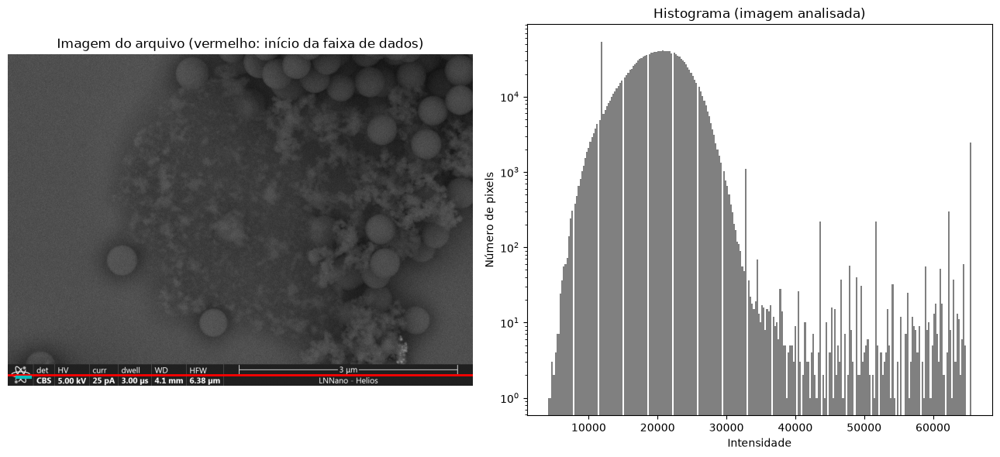

In [13]:
# Faixa de dados do microscópio e calibração do tamanho do pixel

altura_faixa_px = None          # None = detecção automática; 0 = sem faixa de dados; ou o número de linhas a cortar
comprimento_barra_nm = None     # valor escrito na barra de escala, em nm (ex.: 1000 para "1 µm"); só é usado se não houver metadados
tamanho_pixel_nm = None         # se informado (nm/pixel), tem prioridade sobre os metadados e sobre a barra de escala

faixa = None
if altura_faixa_px is None:
    faixa = detectar_faixa_de_dados(imagem_completa)
elif altura_faixa_px > 0:
    faixa = {'linha_inicio': imagem_completa.shape[0] - int(altura_faixa_px),
             'fundo': int(np.bincount(imagem_completa[-1].astype(np.int64)).argmax())}
barra = detectar_barra_de_escala_sem(imagem_completa, faixa) if faixa is not None else None

if faixa is not None:
    print('Faixa de dados: %d linhas (a partir da linha %d)' % (imagem_completa.shape[0] - faixa['linha_inicio'], faixa['linha_inicio']))
else:
    print('Nenhuma faixa de dados detectada: a imagem inteira será analisada.')
if barra is not None:
    print('Barra de escala detectada na faixa: %d pixels' % barra['comprimento_px'])

origem_calibracao = None
if tamanho_pixel_nm is not None:
    origem_calibracao = 'informado manualmente'
else:
    tamanho_pixel_nm, origem_calibracao = ler_calibracao_metadados(filename)
    if tamanho_pixel_nm is None and barra is not None and comprimento_barra_nm is not None:
        tamanho_pixel_nm = comprimento_barra_nm / barra['comprimento_px']
        origem_calibracao = 'barra de escala (%d pixels = %g nm)' % (barra['comprimento_px'], comprimento_barra_nm)

if tamanho_pixel_nm is not None:
    print('Tamanho do pixel: %.4f nm/pixel  [%s]' % (tamanho_pixel_nm, origem_calibracao))
else:
    print('Aviso: tamanho do pixel desconhecido. Informe tamanho_pixel_nm ou comprimento_barra_nm (valor escrito na barra); sem isso, as escalas serão em pixels.')

# A faixa de dados é removida da análise
imagem_raw = imagem_completa[:faixa['linha_inicio']] if faixa is not None else imagem_completa
imagem_original = imagem_raw.astype(np.float32)
scan_height, scan_width = imagem_raw.shape
mascara_valida = np.ones(imagem_raw.shape, dtype=bool)
if tamanho_pixel_nm is not None:
    print('Campo de visão: %.1f x %.1f µm' % (scan_width * tamanho_pixel_nm / 1e3, scan_height * tamanho_pixel_nm / 1e3))

fig, eixos = plt.subplots(1, 2, figsize=(13, 6))
eixos[0].imshow(imagem_completa, cmap='gray')
if faixa is not None:
    eixos[0].axhline(faixa['linha_inicio'], color='r', linewidth=2)
    if barra is not None:
        eixos[0].plot([0.02 * scan_width, 0.02 * scan_width + barra['comprimento_px']], [barra['linha']] * 2, color='c', linewidth=3)
eixos[0].set_title('Imagem do arquivo (vermelho: início da faixa de dados)')
eixos[0].axis('off')
eixos[1].hist(imagem_raw.ravel(), bins=256, color='gray')
eixos[1].set_yscale('log')
eixos[1].set_xlabel('Intensidade'); eixos[1].set_ylabel('Número de pixels'); eixos[1].set_title('Histograma (imagem analisada)')
plt.tight_layout(); plt.show()

Desvio padrão dos deslocamentos de linha removidos: 191.775 níveis de cinza


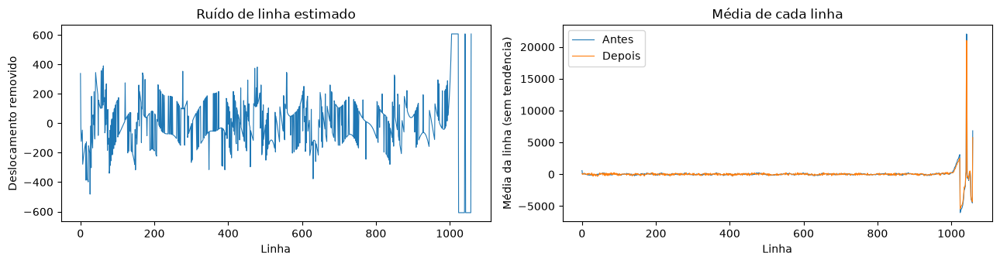

In [14]:
# Correção do ruído de linha da varredura (deslocamentos de brilho entre linhas)

dataset = imagem_original.copy()
corrigir_linhas = True
sigma_linhas = 12.0          # linhas; só deslocamentos mais rápidos que isso são removidos

desloc_linhas = np.zeros(dataset.shape[0])
if corrigir_linhas:
    medias_antes = dataset.mean(axis=1)
    dataset, desloc_linhas = corrigir_listras_de_varredura(dataset, sigma_linhas)
    print('Desvio padrão dos deslocamentos de linha removidos: %.3f níveis de cinza' % desloc_linhas.std())

    fig, eixos = plt.subplots(1, 2, figsize=(13, 3.5))
    eixos[0].plot(desloc_linhas, linewidth=0.8); eixos[0].set_xlabel('Linha'); eixos[0].set_ylabel('Deslocamento removido'); eixos[0].set_title('Ruído de linha estimado')
    eixos[1].plot(medias_antes - ndimage.gaussian_filter1d(medias_antes, 12), linewidth=0.8, label='Antes')
    eixos[1].plot(dataset.mean(axis=1) - ndimage.gaussian_filter1d(dataset.mean(axis=1), 12), linewidth=0.8, label='Depois')
    eixos[1].set_xlabel('Linha'); eixos[1].set_ylabel('Média da linha (sem tendência)'); eixos[1].legend(); eixos[1].set_title('Média de cada linha')
    plt.tight_layout(); plt.show()

Pixels isolados corrigidos: 780


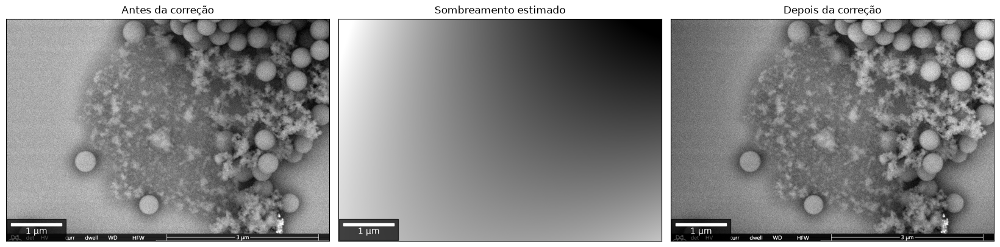

(<Figure size 1650x550 with 3 Axes>,
 array([<Axes: title={'center': 'Antes da correção'}>,
        <Axes: title={'center': 'Sombreamento estimado'}>,
        <Axes: title={'center': 'Depois da correção'}>], dtype=object))

In [15]:
# Remoção de pixels quentes e correção de sombreamento (flatfield)

# Pixels quentes
dataset, n_quentes = remover_pixels_quentes(dataset, limiar_sigma=6.0, mascara=mascara_valida)
print('Pixels isolados corrigidos:', n_quentes)

# Sombreamento do detector
if usar_flatfield_externo:
    flatfield = tifffile.imread(flat_field).astype('float32')
    if flatfield.shape != dataset.shape:
        raise ValueError('O flatfield deve ter a mesma dimensão da imagem analisada: ' + str(flatfield.shape) + ' != ' + str(dataset.shape))
    fundo = flatfield
else:
    # rejeição simétrica: partículas claras e poros escuros não entram no ajuste do sombreamento
    fundo = estimar_fundo_polinomial(dataset, mascara_valida, ordem=ordem_polinomio, k_baixo=2.5, k_alto=2.5)

dataset_sem_flat = dataset.copy()
if modo_flatfield == 'aditivo':
    dataset = dataset - fundo + fundo.mean()
else:
    dataset = dataset / fundo * fundo.mean()
dataset_flat = dataset.copy()

mostrar_imagens([dataset_sem_flat, fundo, dataset_flat],
                ['Antes da correção', 'Sombreamento estimado', 'Depois da correção'],
                pixel_nm=tamanho_pixel_nm, tamanho=5.5)

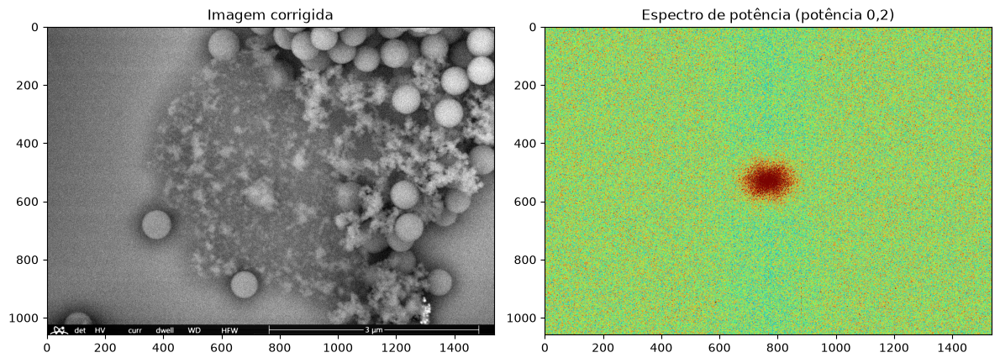

(<Figure size 1200x600 with 2 Axes>,
 array([<Axes: title={'center': 'Imagem corrigida'}>,
        <Axes: title={'center': 'Espectro de potência (potência 0,2)'}>],
       dtype=object))

In [16]:
# Calcula o espectro de potência médio (análogo ao padrão de difração médio)
dp_mean = espectro_de_potencia(dataset)

# plota a imagem corrigida e o espectro de potência
mostrar_imagens(
    [dataset, dp_mean ** 0.2],
    ['Imagem corrigida', 'Espectro de potência (potência 0,2)'],
    cmaps=['gray', 'turbo'],
    tamanho=6,
)

# Calibração e diagnóstico da imagem

Raio de corte do sinal = 457.0 pixels da FFT


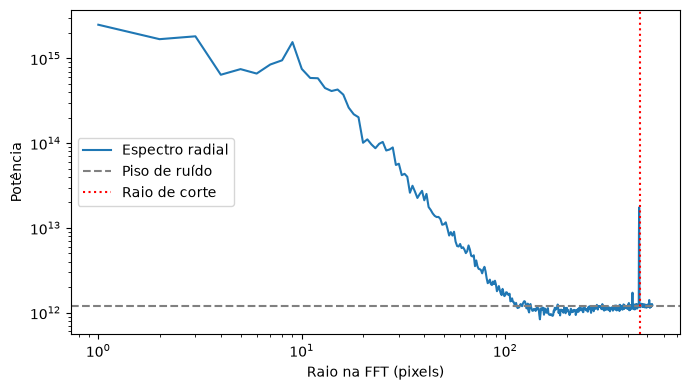

In [17]:
# Estima o raio de corte do sinal no espaço de Fourier (análogo ao raio da sonda)
probe_radius_pixels, perfil_psd, piso_ruido = estimar_raio_de_corte(dp_mean)

# Centro do espaço de Fourier (frequência zero)
probe_qx0, probe_qy0 = scan_width // 2, scan_height // 2

print('Raio de corte do sinal = %.1f pixels da FFT' % probe_radius_pixels)

fig, eixo = plt.subplots(figsize=(7, 4))
eixo.loglog(np.arange(1, len(perfil_psd)), perfil_psd[1:], label='Espectro radial')
eixo.axhline(piso_ruido, color='gray', linestyle='--', label='Piso de ruído')
eixo.axvline(probe_radius_pixels, color='r', linestyle=':', label='Raio de corte')
eixo.set_xlabel('Raio na FFT (pixels)'); eixo.set_ylabel('Potência'); eixo.legend()
plt.tight_layout(); plt.show()

In [18]:
# calibração do tamanho de pixel no espaço real - metadados, barra de escala ou valor manual
# calibração no espaço de Fourier - a partir do tamanho do campo de visão
calibracao = {
    'R_pixel_size': tamanho_pixel_nm if tamanho_pixel_nm is not None else 1.0,
    'R_pixel_units': 'nm' if tamanho_pixel_nm is not None else 'px',
}
calibracao['Q_pixel_size'] = 1.0 / (scan_width * calibracao['R_pixel_size'])
calibracao['Q_pixel_units'] = 'nm^-1' if tamanho_pixel_nm is not None else 'px^-1'
print(calibracao)

# Análise 1 - diagnóstico da imagem
periodo_minimo = scan_width * calibracao['R_pixel_size'] / probe_radius_pixels
m0 = metricas_qualidade(imagem_original, mascara_valida)
m1 = metricas_qualidade(dataset, mascara_valida)
print('')
print('DIAGNÓSTICO DA IMAGEM')
print('Ruído (desvio padrão, níveis de cinza): %.2f' % estimar_ruido(dataset, mascara_valida))
print('SNR: %.2f dB (bruta) -> %.2f dB (corrigida)' % (m0['snr_db'], m1['snr_db']))
print('Menor período com sinal acima do ruído: %.2f %s (resolução efetiva)' % (periodo_minimo, calibracao['R_pixel_units']))
print('Índice de ruído de linha: %.3f níveis de cinza (desvio padrão dos deslocamentos de linha)' % desloc_linhas.std())

{'R_pixel_size': 4.150639999999999, 'R_pixel_units': 'nm', 'Q_pixel_size': 0.00015685332061240358, 'Q_pixel_units': 'nm^-1'}

DIAGNÓSTICO DA IMAGEM
Ruído (desvio padrão, níveis de cinza): 2241.25
SNR: 3.38 dB (bruta) -> 1.45 dB (corrigida)
Menor período com sinal acima do ruído: 13.95 nm (resolução efetiva)
Índice de ruído de linha: 191.775 níveis de cinza (desvio padrão dos deslocamentos de linha)


# Imagens virtuais
### Decomposição em escalas: campo claro (passa-baixa) e campos escuros (passa-faixa) no espaço de Fourier

Campo claro: raio = 20.0 | Campo escuro: raios = (23.0, 102.5) | Campo escuro fino: raios = (102.5, 457.0) pixels da FFT


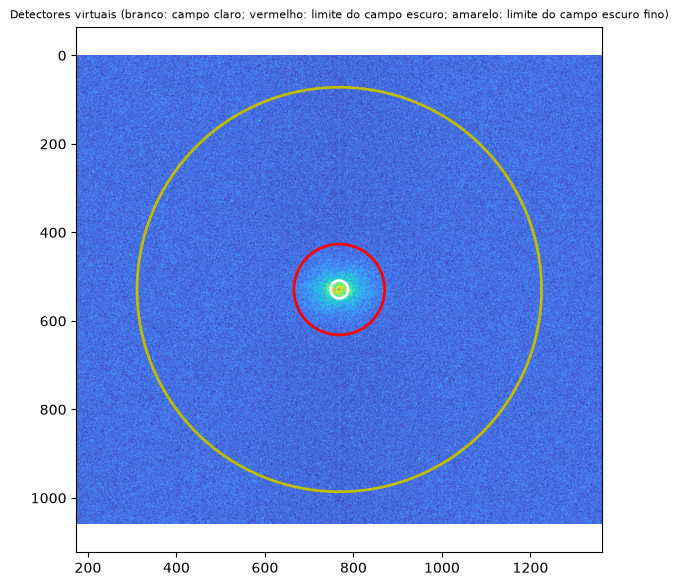

In [19]:
# Cálculo das imagens virtuais de campo claro e de campo escuro

# Estruturas com período maior que este valor (nm; em pixels se não houver calibração) vão para o campo claro.
# Padrão: 5% do campo de visão.
periodo_BF = 0.05 * scan_width * calibracao['R_pixel_size']
periodo_BF_px = periodo_BF / calibracao['R_pixel_size']

# expande o raio em 3 pixels para evitar sobreposição entre os detectores
expand_BF = 3.0

center = (probe_qx0, probe_qy0)
radius_BF = scan_width / periodo_BF_px
radius_mid = float(np.sqrt((radius_BF + expand_BF) * probe_radius_pixels))      # fronteira entre escalas médias e finas
radii_DF = (radius_BF + expand_BF, radius_mid)
radii_DF_fino = (radius_mid, probe_radius_pixels)
if radii_DF[0] >= radii_DF[1] or radii_DF_fino[0] >= radii_DF_fino[1]:
    raise ValueError('periodo_BF incompatível com o raio de corte do sinal; ajuste periodo_BF.')

bright_field = imagem_virtual_fourier(dataset, 'circle', (center, radius_BF))
dark_field = imagem_virtual_fourier(dataset, 'annulus', (center, radii_DF))
dark_field_fino = imagem_virtual_fourier(dataset, 'annulus', (center, radii_DF_fino))

print('Campo claro: raio = %.1f | Campo escuro: raios = (%.1f, %.1f) | Campo escuro fino: raios = (%.1f, %.1f) pixels da FFT' % ((radius_BF,) + radii_DF + radii_DF_fino))

# posição dos detectores no espaço de Fourier
fig, eixo = plt.subplots(figsize=(6, 6))
eixo.imshow(dp_mean ** 0.2, cmap='turbo')
eixo.add_patch(patches.Circle(center, radius_BF, fill=False, edgecolor='w', linewidth=2))
for raio_i, cor in ((radii_DF[1], 'r'), (radii_DF_fino[1], 'y')):
    eixo.add_patch(patches.Circle(center, raio_i, fill=False, edgecolor=cor, linewidth=2))
eixo.set_title('Detectores virtuais (branco: campo claro; vermelho: limite do campo escuro; amarelo: limite do campo escuro fino)', fontsize=8)
eixo.set_xlim(center[0] - 1.3 * radii_DF_fino[1], center[0] + 1.3 * radii_DF_fino[1])
eixo.set_ylim(center[1] + 1.3 * radii_DF_fino[1], center[1] - 1.3 * radii_DF_fino[1])
plt.tight_layout(); plt.show()

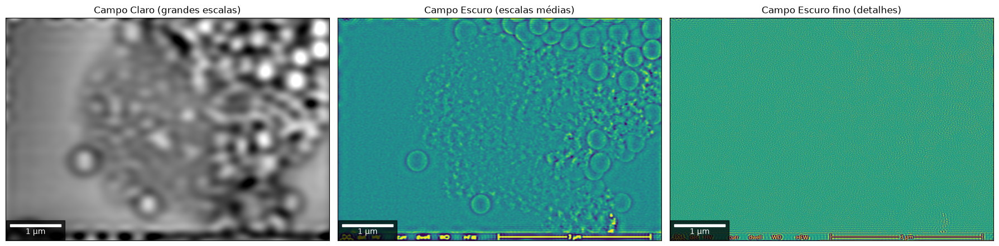

(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'Campo Claro (grandes escalas)'}>,
        <Axes: title={'center': 'Campo Escuro (escalas médias)'}>,
        <Axes: title={'center': 'Campo Escuro fino (detalhes)'}>],
       dtype=object))

In [20]:
# plota as imagens virtuais
mostrar_imagens(
    [bright_field, dark_field, dark_field_fino],
    ['Campo Claro (grandes escalas)', 'Campo Escuro (escalas médias)', 'Campo Escuro fino (detalhes)'],
    cmaps=['gray', 'viridis', 'viridis'],
    pixel_nm=tamanho_pixel_nm,
    tamanho=6,
)

Grandes escalas  | períodos de ∞ a 318.8 nm | 39.5% da variância
Escalas médias   | períodos de 318.8 a 62.2 nm | 19.9% da variância
Detalhes finos   | períodos de 62.2 a 14.0 nm | 40.6% da variância


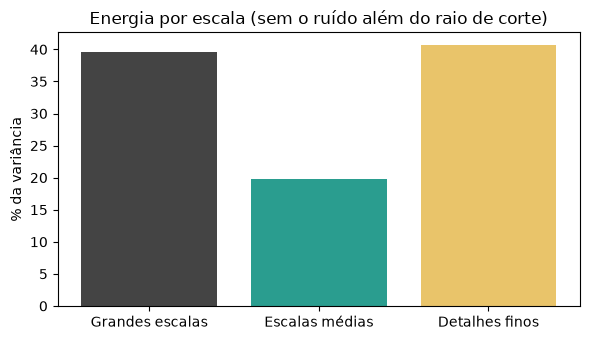

In [21]:
# Análise 2 - energia por escala: fração da variância da imagem em cada faixa de tamanhos

bandas = [('Grandes escalas', bright_field, (np.inf, periodo_BF_px)),
          ('Escalas médias', dark_field, (periodo_BF_px, scan_width / radius_mid)),
          ('Detalhes finos', dark_field_fino, (scan_width / radius_mid, scan_width / probe_radius_pixels))]
variancias = np.array([np.var(b[1] - b[1].mean()) for b in bandas])
fracao_energia = variancias / variancias.sum()
unidade_p = calibracao['R_pixel_units']
fator_p = calibracao['R_pixel_size']

for (nome, _, (p_max, p_min)), f in zip(bandas, fracao_energia):
    print('%-16s | períodos de %s a %.1f %s | %.1f%% da variância' % (nome, ('%.1f' % (p_max * fator_p)) if np.isfinite(p_max) else '∞', p_min * fator_p, unidade_p, 100 * f))

plt.figure(figsize=(6, 3.5))
plt.bar([b[0] for b in bandas], 100 * fracao_energia, color=['#444', '#2a9d8f', '#e9c46a'])
plt.ylabel('% da variância'); plt.title('Energia por escala (sem o ruído além do raio de corte)')
plt.tight_layout(); plt.show()

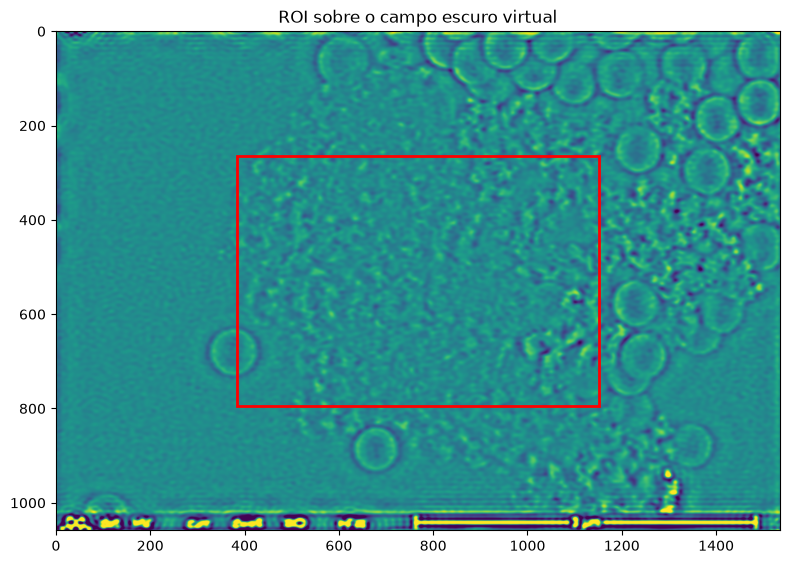

In [22]:
# Verificação da ROI (região de interesse)

# ROI1 = (linha_min, linha_max, coluna_min, coluna_max), em pixels da imagem analisada.
# Por padrão: a região central (metade da largura e da altura).
ROI1 = (scan_height // 4, 3 * scan_height // 4, scan_width // 4, 3 * scan_width // 4)

fig, eixo = plt.subplots(figsize=(8, 8))
eixo.imshow(dark_field, cmap='viridis', vmin=np.percentile(dark_field, 0.5), vmax=np.percentile(dark_field, 99.5))
eixo.add_patch(patches.Rectangle((ROI1[2], ROI1[0]), ROI1[3] - ROI1[2], ROI1[1] - ROI1[0], fill=False, edgecolor='r', linewidth=2))
eixo.set_title('ROI sobre o campo escuro virtual')
plt.tight_layout(); plt.show()

In [23]:
# Redução do conjunto de dados (binning, recorte)

dataset_backup = dataset.copy()

# Recorte da imagem (ROI1). Por padrão a imagem inteira é analisada; use True para analisar só a ROI1.
aplicar_recorte = False

# Fatores de binning
R_bin_factor = 1

recorte = (slice(ROI1[0], ROI1[1]), slice(ROI1[2], ROI1[3])) if aplicar_recorte else (slice(None), slice(None))
dataset = agrupar_pixels(dataset_backup[recorte], R_bin_factor)
imagem_original_roi = agrupar_pixels(imagem_original[recorte], R_bin_factor)
bright_field_roi = agrupar_pixels(bright_field[recorte], R_bin_factor)
dark_field_roi = agrupar_pixels(dark_field[recorte], R_bin_factor)
mascara_roi = np.ones(dataset.shape, dtype=bool)
tamanho_pixel_roi = tamanho_pixel_nm * R_bin_factor if tamanho_pixel_nm is not None else None

print('Dimensões do conjunto analisado:', dataset.shape)
if tamanho_pixel_roi is not None:
    print('Tamanho do pixel: %.4f nm' % tamanho_pixel_roi)

Dimensões do conjunto analisado: (1059, 1536)
Tamanho do pixel: 4.1506 nm


In [24]:
# Salva a região recortada (desative o comentário se quiser gravar)
# tifffile.imwrite(
#     os.path.splitext(filename)[0] + '_SAIDA_recorte.tif',
#     dataset.astype(np.float32),
# )

# Pré-processamento em etapas (perfis SCIENTIFIC e VISUAL)
Equilíbrio tonal, gama, redução de ruído Non-Local Means, CLAHE, suavização controlada, nitidez e ajuste tonal final.
- **SCIENTIFIC**: preserva a informação estrutural. - **VISUAL**: suavidade e destaque dos contornos.

In [25]:
# Parâmetros - Versão A: SCIENTIFIC
parametros_scientific = {
    'black_point': 0.3,
    'white_point': 99.7,
    'gamma': 0.98,

    'denoise_strength': 'auto',   # 'auto' = proporcional ao ruído medido (ou um valor fixo de h)
    'denoise_fator': 0.6,

    'clahe_limit': 1.0,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.05,
    'smooth_sigma': 0.6,

    'sharp_strength': 0.25,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.1, 99.9),
}

# Parâmetros - Versão B: VISUAL
parametros_visual = {
    'black_point': 0.5,
    'white_point': 99.7,
    'gamma': 0.95,

    'denoise_strength': 'auto',
    'denoise_fator': 1.0,

    'clahe_limit': 1.5,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.15,
    'smooth_sigma': 0.8,

    'sharp_strength': 0.40,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.2, 99.8),
}

Força do filtro Non-Local Means (h): scientific = 15.10 | visual = 25.38
Versão SCIENTIFIC | média = 0.4430 | desvio padrão = 0.1801 | mín = 0.000 | máx = 1.000
Versão VISUAL | média = 0.4558 | desvio padrão = 0.1744 | mín = 0.000 | máx = 1.000


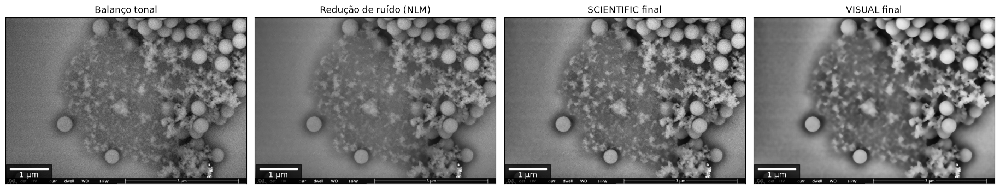

(<Figure size 1840x460 with 4 Axes>,
 array([<Axes: title={'center': 'Balanço tonal'}>,
        <Axes: title={'center': 'Redução de ruído (NLM)'}>,
        <Axes: title={'center': 'SCIENTIFIC final'}>,
        <Axes: title={'center': 'VISUAL final'}>], dtype=object))

In [26]:
# Execução das duas versões sobre a região analisada

resultados_scientific = processar_imagem(dataset, parametros_scientific, mascara_roi)
resultados_visual = processar_imagem(dataset, parametros_visual, mascara_roi)

dataset_norm = resultados_scientific['balance']
dataset_balance = resultados_scientific['balance']
dataset_gamma = resultados_scientific['gamma']
dataset_denoised = resultados_scientific['denoised']
dataset_eq = resultados_scientific['clahe']
dataset_clahe = resultados_scientific['clahe']
dataset_smooth = resultados_scientific['smooth']
dataset_sharp = resultados_scientific['sharp']

dataset_scientific = resultados_scientific['final']
dataset_visual = resultados_visual['final']

print('Força do filtro Non-Local Means (h): scientific = %.2f | visual = %.2f' % (resultados_scientific['h_nlm'], resultados_visual['h_nlm']))
for nome, img in (('SCIENTIFIC', dataset_scientific), ('VISUAL', dataset_visual)):
    print('Versão', nome, '| média = %.4f | desvio padrão = %.4f | mín = %.3f | máx = %.3f' % (img.mean(), img.std(), img.min(), img.max()))

mostrar_imagens([dataset_norm, dataset_denoised, dataset_scientific, dataset_visual],
                ['Balanço tonal', 'Redução de ruído (NLM)', 'SCIENTIFIC final', 'VISUAL final'],
                pixel_nm=tamanho_pixel_roi, vlims=[(0, 1)] * 4, tamanho=4.6)

# Cálculo do gradiente (análogo ao CoM)
### Campo de gradiente, bordas, imagem integrada (DPC) e relevo aparente

Densidade de bordas: 1.91% dos pixels
Comprimento de borda aproximado: 4.60 µm de borda por µm² de imagem


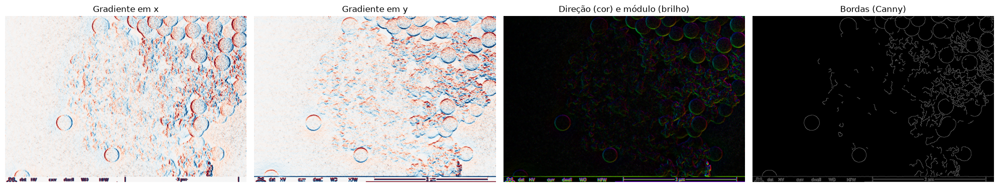

In [27]:
# Inicializa a análise do gradiente: campo de gradiente da imagem sem ruído (análogo ao campo de CoM)

sigma_gradiente = 1.5      # pixels (suavização antes de derivar)
gx, gy = campo_de_gradiente(dataset_denoised, sigma_gradiente)

dpc = SimpleNamespace(
    datacube=dataset_denoised,
    name='dpc_image',
    gx=gx,
    gy=gy,
)
modulo_gradiente = np.hypot(gx, gy)

# Mapa de bordas (Canny) e densidade de bordas
bordas = feature.canny(dataset_denoised, sigma=2.0)
print('Densidade de bordas: %.2f%% dos pixels' % (100 * bordas.mean()))
if tamanho_pixel_roi is not None:
    area_um2 = dataset.size * (tamanho_pixel_roi / 1e3) ** 2
    print('Comprimento de borda aproximado: %.2f µm de borda por µm² de imagem' % (bordas.sum() * tamanho_pixel_roi / 1e3 / area_um2))

fig, eixos = plt.subplots(1, 4, figsize=(20, 5))
v = np.percentile(np.abs(gx), 99)
eixos[0].imshow(gx, cmap='RdBu_r', vmin=-v, vmax=v); eixos[0].set_title('Gradiente em x')
eixos[1].imshow(gy, cmap='RdBu_r', vmin=-v, vmax=v); eixos[1].set_title('Gradiente em y')
eixos[2].imshow(cor_do_gradiente(gx, gy)); eixos[2].set_title('Direção (cor) e módulo (brilho)')
eixos[3].imshow(bordas, cmap='gray'); eixos[3].set_title('Bordas (Canny)')
for e in eixos: e.axis('off')
plt.tight_layout(); plt.show()

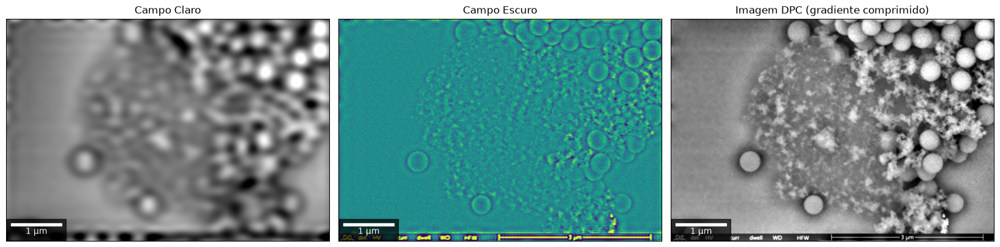

(<Figure size 1650x550 with 3 Axes>,
 array([<Axes: title={'center': 'Campo Claro'}>,
        <Axes: title={'center': 'Campo Escuro'}>,
        <Axes: title={'center': 'Imagem DPC (gradiente comprimido)'}>],
       dtype=object))

In [28]:
# Reconstrução DPC: compressão do gradiente e integração por Fourier (realce de contraste local)

beta_compressao = 0.85     # 1,0 = sem compressão; valores menores atenuam bordas fortes e realçam detalhes fracos
q_highpass = 3.0           # pixels da FFT; suprime as frequências mais baixas

gx_c, gy_c = comprimir_gradiente(dpc.gx, dpc.gy, beta=beta_compressao)
dpc.object_phase = integrar_gradiente_fourier(gx_c, gy_c, q_highpass=q_highpass)

mostrar_imagens(
    [bright_field_roi, dark_field_roi, dpc.object_phase],
    ['Campo Claro', 'Campo Escuro', 'Imagem DPC (gradiente comprimido)'],
    cmaps=['gray', 'viridis', 'gray'],
    pixel_nm=tamanho_pixel_roi,
)

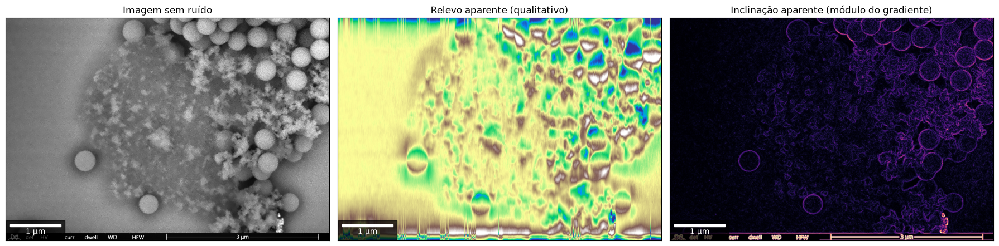

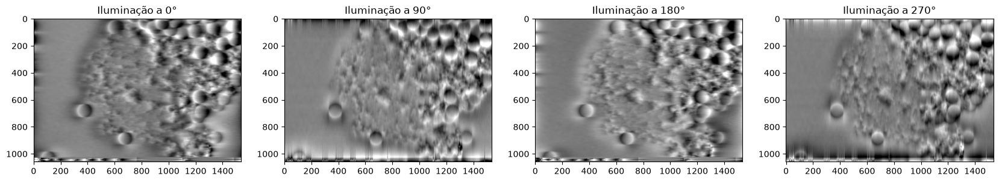

(<Figure size 1680x420 with 4 Axes>,
 array([<Axes: title={'center': 'Iluminação a 0°'}>,
        <Axes: title={'center': 'Iluminação a 90°'}>,
        <Axes: title={'center': 'Iluminação a 180°'}>,
        <Axes: title={'center': 'Iluminação a 270°'}>], dtype=object))

In [29]:
# Análise 3 - relevo aparente (shape-from-shading): resultado QUALITATIVO, sem unidade de altura
# Em imagens de elétrons secundários o brilho depende da inclinação local da superfície em relação ao detector.

angulo_iluminacao = 90.0     # direção aparente da iluminação (graus a partir do eixo x, anti-horário; 90 = vinda de cima)
q_highpass_relevo = 6.0      # pixels da FFT; suprime variações muito lentas

relevo = relevo_aparente(dataset_denoised, angulo_iluminacao, q_highpass_relevo)
inclinacao_aparente = modulo_gradiente

mostrar_imagens([dataset_denoised, relevo, inclinacao_aparente],
                ['Imagem sem ruído', 'Relevo aparente (qualitativo)', 'Inclinação aparente (módulo do gradiente)'],
                cmaps=['gray', 'terrain', 'magma'], pixel_nm=tamanho_pixel_roi, tamanho=6)

# Sensibilidade à direção da iluminação: compare e escolha o ângulo que parece mais coerente com a amostra
angulos_teste = (0, 90, 180, 270)
mostrar_imagens([relevo_aparente(dataset_denoised, a, q_highpass_relevo) for a in angulos_teste],
                ['Iluminação a %d°' % a for a in angulos_teste], cmap='gray', tamanho=4.2)

Nível dominante (I0): 19639.27


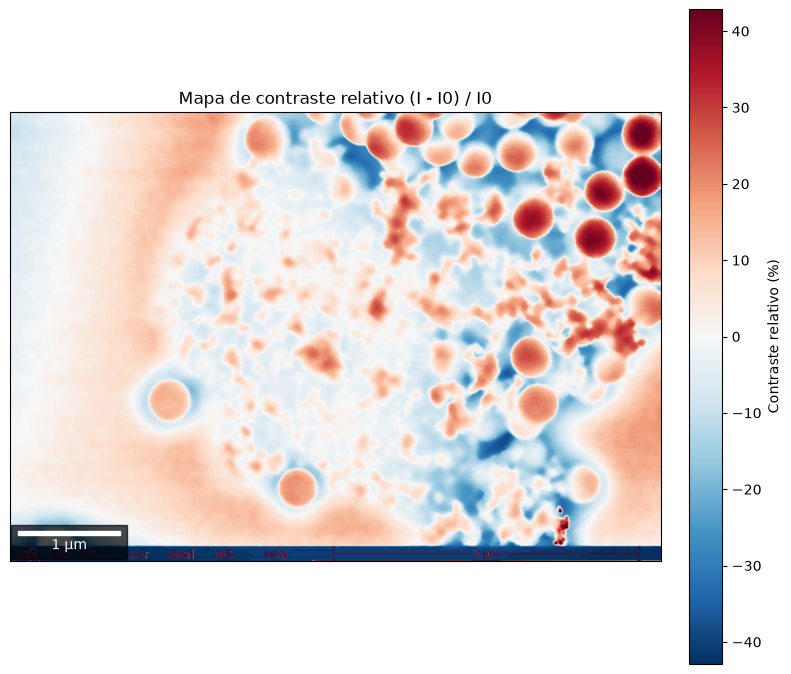

In [30]:
# Análise 4 - mapa de contraste relativo (análogo ao mapa de espessura relativa do TEM): contraste = 100 * (I - I0) / I0
# SE: topografia, carregamento e sombreamento. BSE: composição (número atômico médio); I0 = nível dominante da imagem.

# Suaviza em escala linear de intensidade (sem gama nem CLAHE)
escala_lin = 1.0 / np.percentile(dataset, 99.9)
linear = reduzir_ruido(np.clip(dataset * escala_lin, 0, 1), resultados_scientific['h_nlm']) / escala_lin

I0 = estimar_nivel_dominante(linear, mascara_roi)
contraste_relativo = 100.0 * (linear - I0) / I0
print('Nível dominante (I0): %.2f' % I0)

lim = np.percentile(np.abs(contraste_relativo), 99)
fig, eixo = plt.subplots(figsize=(8, 7))
im = eixo.imshow(contraste_relativo, cmap='RdBu_r', vmin=-lim, vmax=lim)
plt.colorbar(im, ax=eixo, fraction=0.046, pad=0.04, label='Contraste relativo (%)')
eixo.set_title('Mapa de contraste relativo (I - I0) / I0')
if tamanho_pixel_roi is not None:
    adicionar_barra_de_escala(eixo, tamanho_pixel_roi, dataset.shape[1])
    eixo.set_xticks([]); eixo.set_yticks([])
plt.tight_layout(); plt.show()

Fase 1 (nível de cinza até 17013.8): 10.2% da área = 2.9 µm²
Fase 2 (nível de cinza de 17013.8 a 21060.2): 61.8% da área = 17.3 µm²
Fase 3 (nível de cinza acima de 21060.2): 27.9% da área = 7.8 µm²


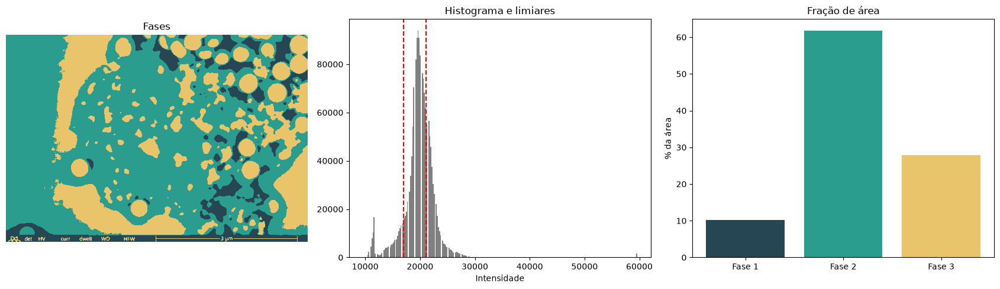

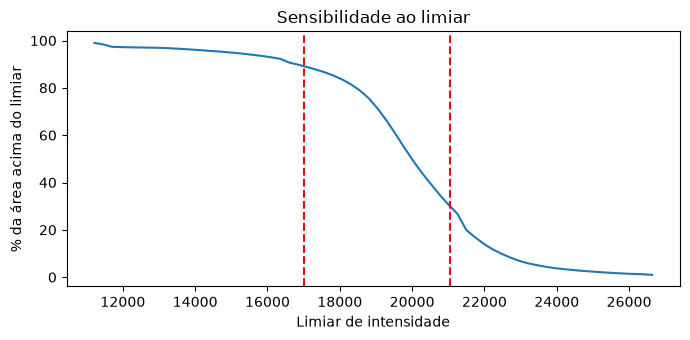

In [31]:
# Análise 5 - fases por níveis de cinza (multi-Otsu), frações de área e sensibilidade ao limiar
from matplotlib.colors import ListedColormap

n_fases = 3
rotulos_fases, limiares_fases, fracoes_fases = segmentar_fases(linear, mascara_roi, n_fases)
cores_fases = ['#264653', '#2a9d8f', '#e9c46a', '#f4a261', '#e76f51'][:n_fases]

fator_area = (tamanho_pixel_roi / 1e3) ** 2 if tamanho_pixel_roi is not None else 1.0
unidade_area = 'µm²' if tamanho_pixel_roi is not None else 'pixels²'
for k in range(n_fases):
    print('Fase %d (nível de cinza %s): %.1f%% da área = %.1f %s' % (k + 1, 'até %.1f' % limiares_fases[0] if k == 0 else ('acima de %.1f' % limiares_fases[-1] if k == n_fases - 1 else 'de %.1f a %.1f' % (limiares_fases[k - 1], limiares_fases[k])), 100 * fracoes_fases[k], fracoes_fases[k] * dataset.size * fator_area, unidade_area))

fig, eixos = plt.subplots(1, 3, figsize=(17, 5))
eixos[0].imshow(rotulos_fases, cmap=ListedColormap(cores_fases), interpolation='nearest'); eixos[0].set_title('Fases'); eixos[0].axis('off')
eixos[1].hist(linear.ravel(), bins=256, color='gray')
for t in limiares_fases:
    eixos[1].axvline(t, color='r', linestyle='--')
eixos[1].set_title('Histograma e limiares'); eixos[1].set_xlabel('Intensidade')
eixos[2].bar(['Fase %d' % (k + 1) for k in range(n_fases)], 100 * np.array(fracoes_fases), color=cores_fases)
eixos[2].set_ylabel('% da área'); eixos[2].set_title('Fração de área')
plt.tight_layout(); plt.show()

# Sensibilidade da fração de área ao limiar: um platô perto do limiar escolhido indica segmentação robusta
limiares_curva, fracao_curva = curva_fracao_vs_limiar(linear, mascara_roi)
plt.figure(figsize=(7, 3.5))
plt.plot(limiares_curva, 100 * fracao_curva)
for t in limiares_fases:
    plt.axvline(t, color='r', linestyle='--')
plt.xlabel('Limiar de intensidade'); plt.ylabel('% da área acima do limiar'); plt.title('Sensibilidade ao limiar')
plt.tight_layout(); plt.show()

# Restauração iterativa (análoga à pticografia)

In [32]:
# Imagem de entrada da restauração (análogo ao bin_Q aplicado antes da pticografia)

Q_bin_factor = 1     # use 2 para reduzir o tempo de cálculo em imagens grandes (perde resolução)
dataset_ptycho = agrupar_pixels(dataset_denoised, Q_bin_factor) + 0.02    # deslocamento pequeno: evita divisão por zero
tamanho_pixel_ptycho = tamanho_pixel_roi * Q_bin_factor if tamanho_pixel_roi is not None else None

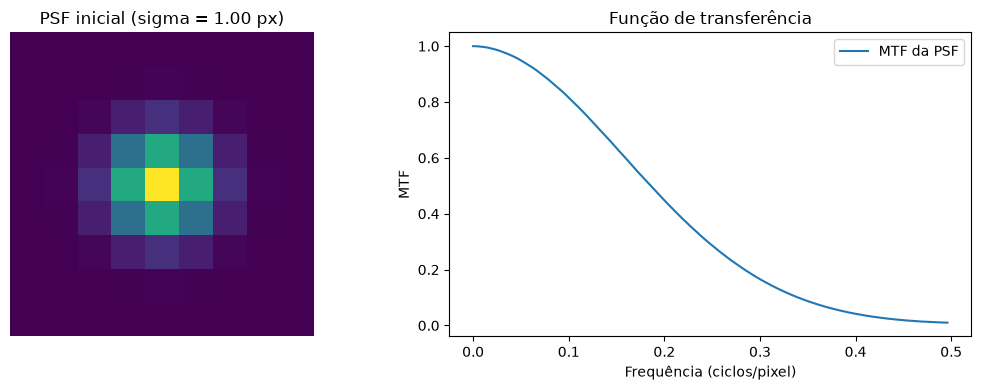

In [33]:
# Restauração Richardson-Lucy com regularização TV (single-slice: um único plano de imagem)

# definição da PSF (análoga à definição da sonda): o perfil do feixe de elétrons na superfície
psf_sigma = 1.0                     # pixels - valor inicial, refinado na etapa 2
object_padding_px = (16, 16)        # preenchimento por reflexão (evita artefatos de borda)
semiangle_cutoff = probe_radius_pixels     # pixels da FFT (raio de corte do sinal)

# Pré-processamento
ptycho = criar_restauracao(
    dataset_ptycho,
    psf_sigma=psf_sigma,
    padding=object_padding_px,
)

# mostra a PSF e sua função de transferência (MTF)
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].imshow(ptycho.probe, cmap='viridis'); eixos[0].set_title('PSF inicial (sigma = %.2f px)' % psf_sigma); eixos[0].axis('off')
mtf = np.abs(np.fft.fftshift(np.fft.fft2(ptycho.probe, s=(256, 256))))
f_mtf = np.arange(128) / 256.0
eixos[1].plot(f_mtf, perfil_radial(mtf)[:128], label='MTF da PSF')
eixos[1].set_xlabel('Frequência (ciclos/pixel)'); eixos[1].set_ylabel('MTF'); eixos[1].set_title('Função de transferência'); eixos[1].legend()
plt.tight_layout(); plt.show()

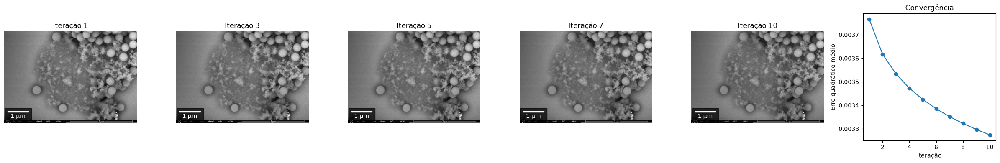

In [34]:
# Etapa 1: iterações com a PSF inicial

ptycho = reconstruir(
    ptycho,
    reset = True,
    num_iter = 10,
    step_size = 1.0,
)
visualizar_iteracoes(ptycho.iterations, ptycho.error_iterations, pixel_nm=tamanho_pixel_ptycho)

Ajuste da PSF inconclusivo (sigma = 0.0); mantendo psf_sigma = 1.00 pixels


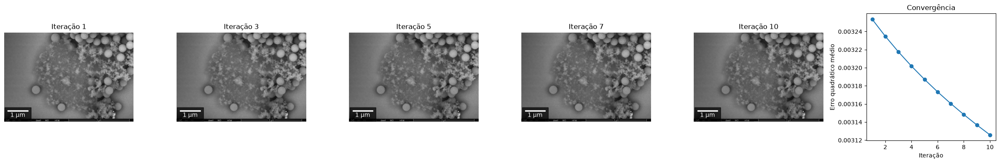

In [35]:
# Etapa 2: ajuste da PSF a partir do espectro de potência (análogo ao ajuste das aberrações da sonda)

sigma_estimado, raios_ajuste, perfil_modelo = ajustar_sigma_psf(dp_mean, probe_radius_pixels, piso_ruido)
# O ajuste só é confiável quando o espectro da própria amostra decai suavemente (como uma lei de potência):
# se o resultado sair da faixa plausível (0,3 a 3 pixels), mantém-se o psf_sigma definido manualmente.
if sigma_estimado is None or not (0.3 <= sigma_estimado <= 3.0):
    print('Ajuste da PSF inconclusivo (sigma = %s); mantendo psf_sigma = %.2f pixels' % (sigma_estimado, psf_sigma))
else:
    print('Sigma da PSF estimado pelo espectro: %.2f pixels' % sigma_estimado)
    ptycho.probe = psf_gaussiana(sigma_estimado)
    ptycho.psf_sigma = sigma_estimado

    fig, eixo = plt.subplots(figsize=(7, 4))
    eixo.loglog(np.arange(1, len(perfil_psd)), perfil_psd[1:], label='Espectro radial medido')
    eixo.loglog(raios_ajuste, perfil_modelo, 'r', label='Modelo ajustado')
    eixo.axhline(piso_ruido, color='gray', linestyle='--', label='Piso de ruído')
    eixo.set_xlabel('Raio na FFT (pixels)'); eixo.set_ylabel('Potência'); eixo.legend()
    plt.tight_layout(); plt.show()

ptycho = reconstruir(
    ptycho,
    reset = False,
    num_iter = 10,
    step_size = 1.0,
)
visualizar_iteracoes(ptycho.iterations[-10:], ptycho.error_iterations[-10:], pixel_nm=tamanho_pixel_ptycho)

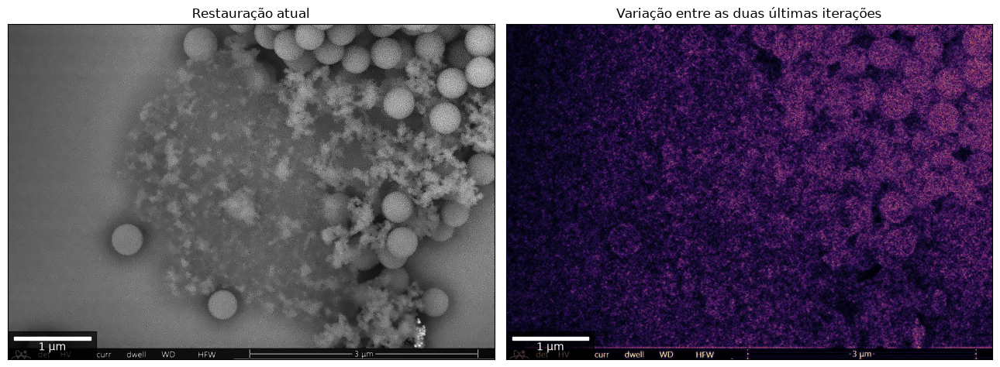

(<Figure size 1300x650 with 2 Axes>,
 array([<Axes: title={'center': 'Restauração atual'}>,
        <Axes: title={'center': 'Variação entre as duas últimas iterações'}>],
       dtype=object))

In [36]:
# Etapa 3: mapa de variação entre as duas últimas iterações (onde a solução ainda muda)

ptycho = reconstruir(
    ptycho,
    reset = False,
    num_iter = 10,
    step_size = 1.0,
)
variacao = np.abs(ptycho.iterations[-1] - ptycho.iterations[-2])

mostrar_imagens([ptycho.object, variacao], ['Restauração atual', 'Variação entre as duas últimas iterações'],
                cmaps=['gray', 'magma'], pixel_nm=tamanho_pixel_ptycho, tamanho=6.5)

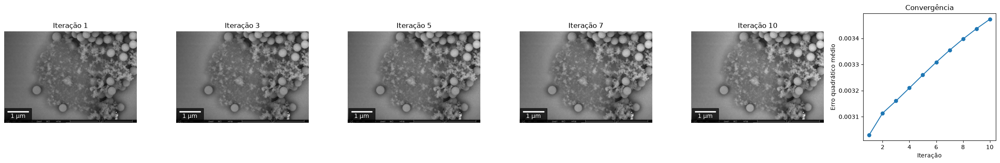

In [37]:
# Etapa 4: restauração final com regularização de variação total (TV)

# Peso da regularização TV (faixa útil: 0,005 a 0,05; valores altos geram oscilações de alta frequência)
tv_denoise_weight = 0.02

ptycho = reconstruir(
    ptycho,
    reset = False,
    num_iter = 10,
    step_size = 1.0,
    tv_denoise_weight = tv_denoise_weight,
)
visualizar_iteracoes(ptycho.iterations[-10:], ptycho.error_iterations[-10:], pixel_nm=tamanho_pixel_ptycho)

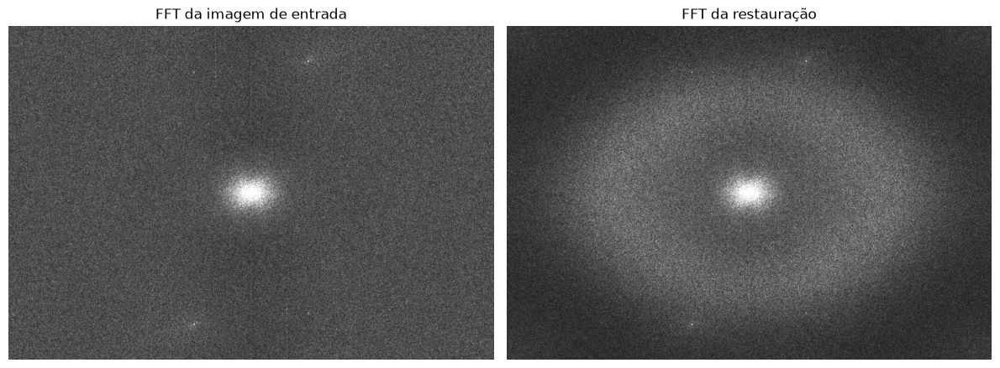

In [38]:
# FFT da imagem antes e depois da restauração
mostrar_fft_objeto(
    dataset_ptycho,
    ptycho.object,
    figsize = (12, 6),
    power = 0.5,
)

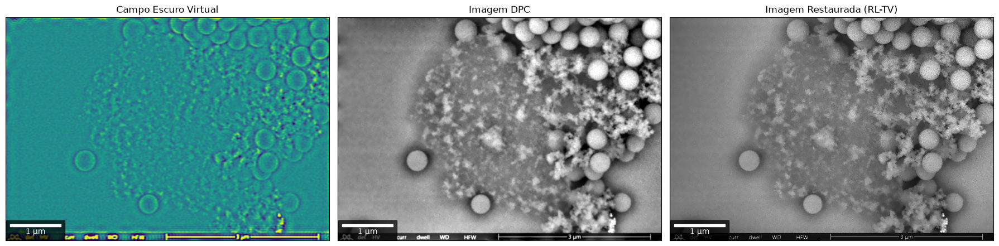

(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'Campo Escuro Virtual'}>,
        <Axes: title={'center': 'Imagem DPC'}>,
        <Axes: title={'center': 'Imagem Restaurada (RL-TV)'}>],
       dtype=object))

In [39]:
obj = ptycho.object
pixelsize = tamanho_pixel_ptycho if tamanho_pixel_ptycho is not None else 1

# #reamostragem
# zoom_factor=(4,4)
# obj2 = ndimage.zoom(obj, zoom_factor)
# pixelsize_obj2 = pixelsize/zoom_factor[0]

mostrar_imagens(
    [agrupar_pixels(dark_field_roi, Q_bin_factor), agrupar_pixels(dpc.object_phase, Q_bin_factor), obj],
    ['Campo Escuro Virtual', 'Imagem DPC', 'Imagem Restaurada (RL-TV)'],
    cmaps=['viridis', 'gray', 'gray'],
    pixel_nm=tamanho_pixel_ptycho,
    tamanho=6,
)

# Análises paralelas sobre a imagem restaurada

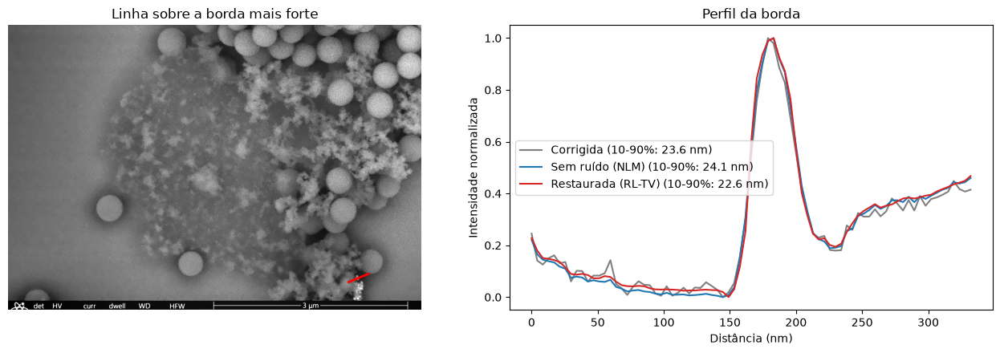

Largura de borda 10-90%: {'Corrigida': 23.62, 'Sem ruído (NLM)': 24.08, 'Restaurada (RL-TV)': 22.61} nm


In [40]:
# Análise 6 - largura de borda (10% a 90%) sobre a borda mais forte, antes e depois da restauração

comprimento_linha = 80        # pixels
largura_media = 9             # pixels (média perpendicular à linha, reduz o ruído)

ref_corrigida = agrupar_pixels(dataset, Q_bin_factor)
ref_sem_ruido = dataset_ptycho - 0.02
p0, p1 = linha_sobre_a_borda_mais_forte(ref_sem_ruido, comprimento_linha)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
eixos[0].imshow(ref_sem_ruido, cmap='gray'); eixos[0].plot([p0[0], p1[0]], [p0[1], p1[1]], 'r-', linewidth=2)
eixos[0].set_title('Linha sobre a borda mais forte'); eixos[0].axis('off')

fator_d = tamanho_pixel_ptycho if tamanho_pixel_ptycho is not None else 1.0
unidade_d = 'nm' if tamanho_pixel_ptycho is not None else 'pixels'
larguras_borda = {}
for nome, img, cor in (('Corrigida', ref_corrigida, 'gray'), ('Sem ruído (NLM)', ref_sem_ruido, 'tab:blue'), ('Restaurada (RL-TV)', obj, 'tab:red')):
    dist, perfil = perfil_de_linha(img, p0, p1, largura_media)
    perfil_n = (perfil - perfil.min()) / (perfil.max() - perfil.min())
    largura, _ = largura_de_borda_10_90(dist, perfil_n)
    larguras_borda[nome] = None if largura is None else largura * fator_d
    eixos[1].plot(dist * fator_d, perfil_n, color=cor, label=nome + ('' if largura is None else ' (10-90%%: %.1f %s)' % (largura * fator_d, unidade_d)))
eixos[1].set_xlabel('Distância (' + unidade_d + ')'); eixos[1].set_ylabel('Intensidade normalizada'); eixos[1].legend(); eixos[1].set_title('Perfil da borda')
plt.tight_layout(); plt.show()
print('Largura de borda 10-90%:', {k: (None if v is None else round(v, 2)) for k, v in larguras_borda.items()}, unidade_d)

Versão                          Ruído   SNR (dB)   Nitidez rel.   Entropia  Contraste
Original (analisada)           0.1095       3.38          0.182      5.925      0.162
Corrigida                      0.1112       1.49          0.244      7.461      0.132
Sem ruído (NLM)                0.0485       8.86          0.231      6.972      0.135
SCIENTIFIC final               0.0799       5.31          0.260      7.502      0.147
VISUAL final                   0.0152      21.57          0.205      7.532      0.182
Restaurada (RL-TV)             0.0291      12.80          0.254      7.113      0.127
Obs.: filtros mais agressivos aumentam o SNR à custa de detalhes; interprete o SNR junto com a nitidez relativa (borda forte / contraste).


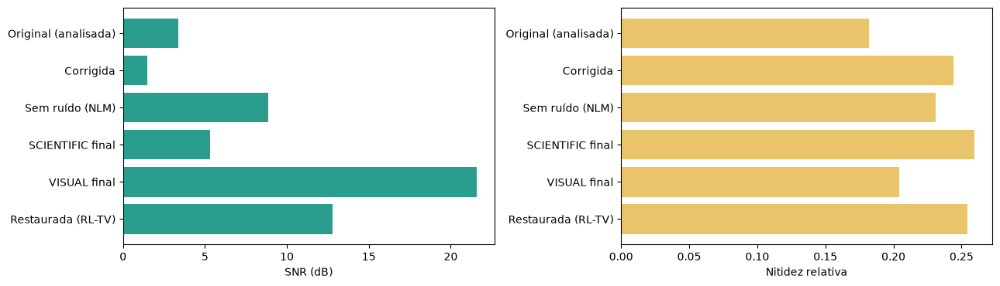

In [41]:
# Análise 7 - tabela de qualidade de todas as versões da imagem (independente da escala de brilho)

versoes = {
    'Original (analisada)': imagem_original_roi,
    'Corrigida': dataset,
    'Sem ruído (NLM)': dataset_denoised,
    'SCIENTIFIC final': dataset_scientific,
    'VISUAL final': dataset_visual,
    'Restaurada (RL-TV)': obj,
}
metricas_versoes = {nome: metricas_qualidade(img) for nome, img in versoes.items()}
imprimir_tabela_metricas(metricas_versoes)

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
nomes = list(metricas_versoes)
eixos[0].barh(nomes, [metricas_versoes[n]['snr_db'] for n in nomes], color='#2a9d8f'); eixos[0].set_xlabel('SNR (dB)'); eixos[0].invert_yaxis()
eixos[1].barh(nomes, [metricas_versoes[n]['nitidez_rel'] for n in nomes], color='#e9c46a'); eixos[1].set_xlabel('Nitidez relativa'); eixos[1].invert_yaxis()
plt.tight_layout(); plt.show()

Comprimento de correlação (diâmetro equivalente onde a ACF cai a 1/e): 195.3 nm
Eixos da elipse de correlação: 176.0 e 222.0 nm | anisotropia = 1.26 | eixo maior a 179° do eixo x


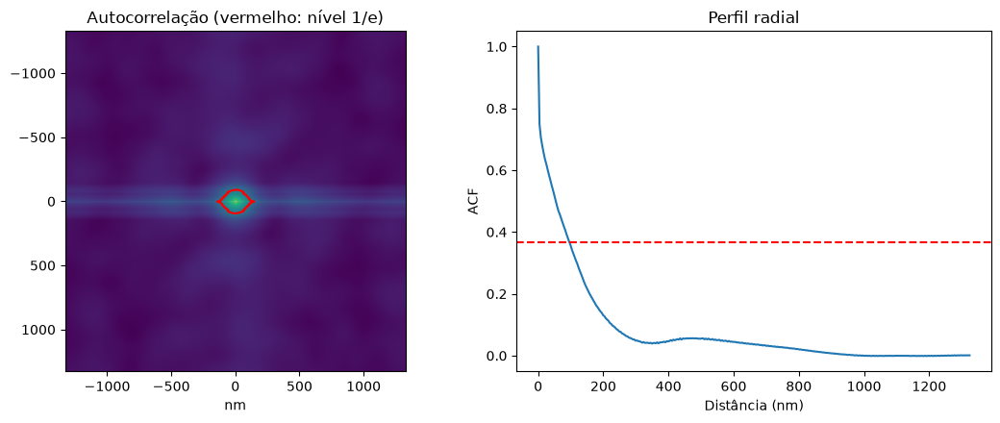

In [42]:
# Análise 8 - autocorrelação 2D: comprimento de correlação e anisotropia (sobre a imagem sem ruído)

res_acf = autocorrelacao_2d(dataset_denoised)
unidade_c = calibracao['R_pixel_units']
fator_c = tamanho_pixel_roi if tamanho_pixel_roi is not None else 1.0
print('Comprimento de correlação (diâmetro equivalente onde a ACF cai a 1/e): %.1f %s' % (res_acf['diametro_eq'] * fator_c, unidade_c))
print('Eixos da elipse de correlação: %.1f e %.1f %s | anisotropia = %.2f | eixo maior a %.0f° do eixo x' % (res_acf['eixos'][0] * fator_c, res_acf['eixos'][1] * fator_c, unidade_c, res_acf['anisotropia'], res_acf['angulo']))

h_a, w_a = res_acf['acf'].shape
meia = int(min(6 * res_acf['eixos'][1], h_a // 2 - 1, w_a // 2 - 1))
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
eixos[0].imshow(res_acf['acf'][h_a // 2 - meia:h_a // 2 + meia, w_a // 2 - meia:w_a // 2 + meia], cmap='viridis',
                extent=(-meia * fator_c, meia * fator_c, meia * fator_c, -meia * fator_c))
eixos[0].contour(np.linspace(-meia * fator_c, meia * fator_c, 2 * meia), np.linspace(-meia * fator_c, meia * fator_c, 2 * meia),
                 res_acf['acf'][h_a // 2 - meia:h_a // 2 + meia, w_a // 2 - meia:w_a // 2 + meia], levels=[np.exp(-1)], colors='r')
eixos[0].set_title('Autocorrelação (vermelho: nível 1/e)'); eixos[0].set_xlabel(unidade_c)
perfil_acf = perfil_radial(res_acf['acf'])[:meia]
eixos[1].plot(np.arange(meia) * fator_c, perfil_acf); eixos[1].axhline(np.exp(-1), color='r', linestyle='--')
eixos[1].set_xlabel('Distância (' + unidade_c + ')'); eixos[1].set_ylabel('ACF'); eixos[1].set_title('Perfil radial')
plt.tight_layout(); plt.show()

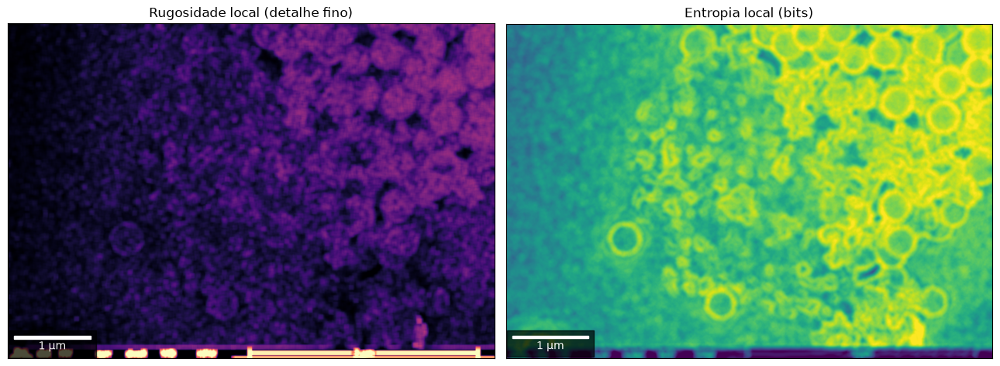

Fase      Contraste    Dissimilar.    Homogeneid.    Energia   Correlação
Fase 1        2.926          1.046          0.617      0.325        0.447
Fase 2        4.436          1.453          0.504      0.245        0.112
Fase 3        9.210          2.130          0.400      0.180        0.015


In [43]:
# Análise 9 - rugosidade e textura local (sobre a imagem sem ruído)

rugosidade = mapa_rugosidade_local(dataset_denoised, sigma_passa_alta=3.0, janela=15)
entropia_local = mapa_entropia_local(dataset_denoised, raio=7, reducao=2)

mostrar_imagens([rugosidade, entropia_local], ['Rugosidade local (detalhe fino)', 'Entropia local (bits)'],
                cmaps=['magma', 'viridis'], pixel_nm=tamanho_pixel_roi, tamanho=6.5)

# Características de textura (GLCM) por fase, em blocos de 32 x 32 pixels inteiramente dentro de cada fase
print('%-8s %10s %14s %14s %10s %12s' % ('Fase', 'Contraste', 'Dissimilar.', 'Homogeneid.', 'Energia', 'Correlação'))
texturas_fases = {}
for k in range(n_fases):
    t = textura_por_regiao(dataset_denoised, rotulos_fases == k)
    texturas_fases[k + 1] = t
    if t is None:
        print('%-8s sem blocos de 32 x 32 pixels totalmente dentro da fase' % ('Fase %d' % (k + 1)))
    else:
        print('%-8s %10.3f %14.3f %14.3f %10.3f %12.3f' % ('Fase %d' % (k + 1), t['contrast'], t['dissimilarity'], t['homogeneity'], t['energy'], t['correlation']))

# Comparação final e salvamento dos resultados

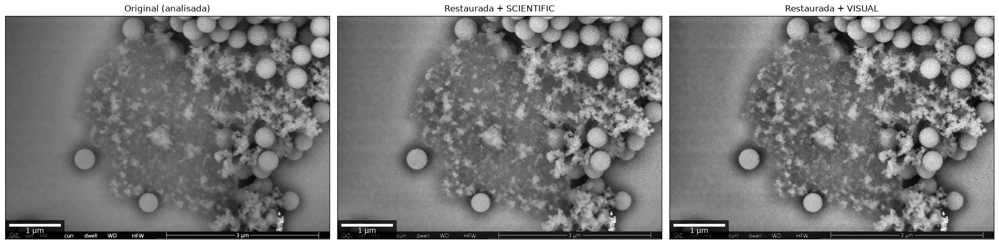

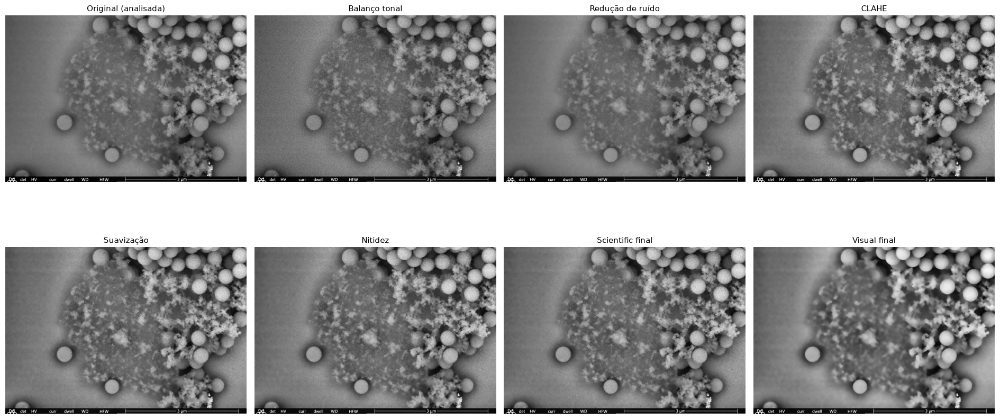

In [44]:
# Realce final da imagem restaurada nas versões SCIENTIFIC e VISUAL

restaurada_scientific = realce_final(obj, parametros_scientific)
restaurada_visual = realce_final(obj, parametros_visual)
referencia = normalizar_percentis(dataset_ptycho - 0.02, (0.5, 99.7))

# Comparação geral
mostrar_imagens(
    [referencia, restaurada_scientific, restaurada_visual],
    ['Original (analisada)', 'Restaurada + SCIENTIFIC', 'Restaurada + VISUAL'],
    pixel_nm=tamanho_pixel_ptycho, vlims=[(0, 1)] * 3, tamanho=6.5,
)

# Comparação das etapas de processamento
etapas = [
    (referencia, 'Original (analisada)'),
    (dataset_balance, 'Balanço tonal'),
    (dataset_denoised, 'Redução de ruído'),
    (dataset_clahe, 'CLAHE'),
    (dataset_smooth, 'Suavização'),
    (dataset_sharp, 'Nitidez'),
    (dataset_scientific, 'Scientific final'),
    (dataset_visual, 'Visual final'),
]
fig, eixos = plt.subplots(2, 4, figsize=(19, 10))
for eixo, (img, titulo) in zip(eixos.flat, etapas):
    eixo.imshow(img, cmap='gray', vmin=0, vmax=1)
    eixo.set_title(titulo, fontsize=11)
    eixo.axis('off')
plt.tight_layout(); plt.show()

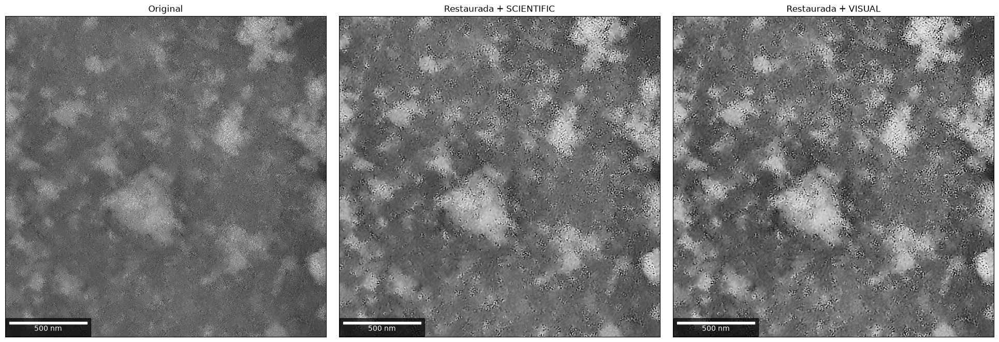

(<Figure size 1950x650 with 3 Axes>,
 array([<Axes: title={'center': 'Original'}>,
        <Axes: title={'center': 'Restaurada + SCIENTIFIC'}>,
        <Axes: title={'center': 'Restaurada + VISUAL'}>], dtype=object))

In [45]:
# Comparação de uma região da microestrutura (recorte central de até 500 x 500 pixels)

alt, larg = obj.shape
meio_y, meio_x = alt // 2, larg // 2
meia = min(250, alt // 2, larg // 2)
y1, y2, x1, x2 = meio_y - meia, meio_y + meia, meio_x - meia, meio_x + meia

mostrar_imagens(
    [referencia[y1:y2, x1:x2], restaurada_scientific[y1:y2, x1:x2], restaurada_visual[y1:y2, x1:x2]],
    ['Original', 'Restaurada + SCIENTIFIC', 'Restaurada + VISUAL'],
    pixel_nm=tamanho_pixel_ptycho, vlims=[(0, 1)] * 3, tamanho=6.5,
)

In [46]:
# Salvamento dos resultados (float32 e uint8) e das tabelas (CSV) na pasta do notebook

base = os.path.splitext(filename)[0] + '_SAIDA_'
imagens_saida = {
    'PLUS_SCIENTIFIC.tif': dataset_scientific,
    'PLUS_VISUAL.tif': dataset_visual,
    'RESTAURADA_SCIENTIFIC.tif': restaurada_scientific,
    'RESTAURADA_VISUAL.tif': restaurada_visual,
    'DPC.tif': dpc.object_phase,
    'RELEVO_APARENTE.tif': relevo,
    'CONTRASTE_RELATIVO.tif': contraste_relativo,
    'RUGOSIDADE_LOCAL.tif': rugosidade,
    'ENTROPIA_LOCAL.tif': entropia_local,
    'FASES.tif': rotulos_fases,
}
for sufixo, imagem_saida in imagens_saida.items():
    dados_saida = np.asarray(imagem_saida)
    dados_saida = dados_saida if dados_saida.dtype == np.uint8 else dados_saida.astype(np.float32)
    tifffile.imwrite(base + sufixo, dados_saida, photometric='minisblack')

with open(base + 'METRICAS_QUALIDADE.csv', 'w', newline='', encoding='utf-8') as f:
    escritor = csv.writer(f)
    escritor.writerow(['versao', 'ruido', 'snr_db', 'nitidez_rel', 'entropia', 'contraste'])
    for nome, m in metricas_versoes.items():
        escritor.writerow([nome, m['ruido'], m['snr_db'], m['nitidez_rel'], m['entropia'], m['contraste']])

with open(base + 'FASES_E_CORRELACAO.csv', 'w', newline='', encoding='utf-8') as f:
    escritor = csv.writer(f)
    escritor.writerow(['grandeza', 'valor', 'unidade'])
    for k in range(n_fases):
        escritor.writerow(['fracao_area_fase_%d' % (k + 1), fracoes_fases[k], 'fracao'])
    escritor.writerow(['comprimento_correlacao', res_acf['diametro_eq'] * fator_c, unidade_c])
    escritor.writerow(['anisotropia_correlacao', res_acf['anisotropia'], ''])
    escritor.writerow(['densidade_de_bordas', float(bordas.mean()), 'fracao_de_pixels'])
    for nome, largura in larguras_borda.items():
        escritor.writerow(['largura_borda_10_90 (' + nome + ')', '' if largura is None else largura, unidade_d])

print('ARQUIVOS SALVOS em', pasta_notebook)
for sufixo in list(imagens_saida) + ['METRICAS_QUALIDADE.csv', 'FASES_E_CORRELACAO.csv']:
    print(os.path.basename(base) + sufixo)

ARQUIVOS SALVOS em C:\JupyterLab\2-semestre\IP1\SEM
MEV-NC_AM_BSE_005_SAIDA_PLUS_SCIENTIFIC.tif
MEV-NC_AM_BSE_005_SAIDA_PLUS_VISUAL.tif
MEV-NC_AM_BSE_005_SAIDA_RESTAURADA_SCIENTIFIC.tif
MEV-NC_AM_BSE_005_SAIDA_RESTAURADA_VISUAL.tif
MEV-NC_AM_BSE_005_SAIDA_DPC.tif
MEV-NC_AM_BSE_005_SAIDA_RELEVO_APARENTE.tif
MEV-NC_AM_BSE_005_SAIDA_CONTRASTE_RELATIVO.tif
MEV-NC_AM_BSE_005_SAIDA_RUGOSIDADE_LOCAL.tif
MEV-NC_AM_BSE_005_SAIDA_ENTROPIA_LOCAL.tif
MEV-NC_AM_BSE_005_SAIDA_FASES.tif
MEV-NC_AM_BSE_005_SAIDA_METRICAS_QUALIDADE.csv
MEV-NC_AM_BSE_005_SAIDA_FASES_E_CORRELACAO.csv
